In [1]:
import os

# Set your W&B token (optional, see USE_WANDB below)
os.environ.setdefault("WANDB_API_KEY", "???")
# os.environ["HF_HOME"] = "/mnt/disks/ai-training/hf_cache"

import math
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
import timm
import lightning.pytorch as pl
import wandb

from einops import rearrange
from skimage import data as skdata
from torch.utils.data import DataLoader, Subset
from torchmetrics.classification import MulticlassAccuracy
from lightning.pytorch.loggers import CSVLogger, WandbLogger
from lightning.pytorch.callbacks import LearningRateMonitor
from timm.data import ImageNetInfo, resolve_data_config

from lecture_utils import (
    get_device, set_seed, count_params, benchmark_fn, denormalize, read_lightning_metrics
)

%matplotlib inline
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", None)

In [2]:
DEVICE = get_device()
# Mixed precision: bf16 where supported (safer than fp16 for attention logits), full precision on CPU
if DEVICE == "cuda":
    PRECISION = "bf16-mixed" if torch.cuda.is_bf16_supported() else "16-mixed"
else:
    PRECISION = {"mps": "bf16-mixed"}.get(DEVICE, "32-true")
NUM_WORKERS = 4
DATA_DIR = "../../data"
RESULTS_DIR = "results"
# Training runs take ~15 min on an RTX 5090 and ~1.5 h on an Apple M-series laptop.
# Set to False to skip training and plot the precomputed results from `results/` instead.
RUN_EXPERIMENTS = True
# Set to True (and provide WANDB_API_KEY) to additionally log runs to W&B. By default we log locally to CSV.
USE_WANDB = False
os.makedirs(RESULTS_DIR, exist_ok=True)

set_seed(95431)
print(f"torch {torch.__version__} | timm {timm.__version__} | device: {DEVICE} | precision: {PRECISION}")

torch 2.8.0+cu128 | timm 1.0.30 | device: cuda | precision: bf16-mixed


# Agenda

1. [From CNNs to Transformers](#From_CNN_to_ViT)
2. [Data](#Data)
3. [Patch Embedding: an image is worth 16x16 words](#Patch_Embedding)
4. [Self-Attention and Multi-Head Self-Attention](#Self_Attention)
5. [Transformer Block](#Transformer_Block)
6. [Order Matters: CLS token and Positional Embeddings](#Positional_Embeddings)
7. [Assembling the Vision Transformer](#Assembling_ViT)
8. [Sanity check: loading pretrained timm weights into our ViT](#Pretrained_Weights)
9. [Looking inside a ViT](#Looking_Inside)
10. [Training ViT: from scratch vs CNN vs pretrained](#Training)
11. [Summary and self-check questions](#Summary)
12. [Appendix: practical tips for fine-tuning](#Practical_Tips)

# Resources

- [Attention Is All You Need (Vaswani et al., 2017)](https://arxiv.org/abs/1706.03762)
- [An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale (ViT, Dosovitskiy et al., 2020)](https://arxiv.org/abs/2010.11929)
- [How to train your ViT? Data, Augmentation, and Regularization in Vision Transformers (AugReg, Steiner et al., 2021)](https://arxiv.org/abs/2106.10270)
- [Better plain ViT baselines for ImageNet-1k (Beyer et al., 2022)](https://arxiv.org/abs/2205.01580)
- [Scaling Vision Transformers (Zhai et al., 2022)](https://arxiv.org/abs/2106.04560)
- [Training data-efficient image transformers & distillation through attention (DeiT, Touvron et al., 2020)](https://arxiv.org/abs/2012.12877)
- [Do Vision Transformers See Like Convolutional Neural Networks? (Raghu et al., 2021)](https://arxiv.org/abs/2108.08810)
- [Quantifying Attention Flow in Transformers (Attention Rollout, Abnar & Zuidema, 2020)](https://arxiv.org/abs/2005.00928)
- [On Layer Normalization in the Transformer Architecture (Pre-LN vs Post-LN, Xiong et al., 2020)](https://arxiv.org/abs/2002.04745)
- [Deep Networks with Stochastic Depth (Huang et al., 2016)](https://arxiv.org/abs/1603.09382)
- [FlashAttention (Dao et al., 2022)](https://arxiv.org/abs/2205.14135)
- [timm: `vision_transformer.py` reference implementation](https://github.com/huggingface/pytorch-image-models/blob/main/timm/models/vision_transformer.py)
- [google-research/vision_transformer (original JAX code)](https://github.com/google-research/vision_transformer)
- [lucidrains/vit-pytorch](https://github.com/lucidrains/vit-pytorch)
- [The Illustrated Transformer (Jay Alammar)](https://jalammar.github.io/illustrated-transformer/)

<a id='From_CNN_to_ViT'></a>
# From CNNs to Transformers

<img src="https://raw.githubusercontent.com/google-research/vision_transformer/main/vit_figure.png" width="700">

In the previous Computer Vision course we treated ViT mostly as a *black box* from `timm`. Today we open that box and write every line of it ourselves.

## Why would we want anything other than a CNN?

A convolution hard-codes two very strong assumptions (**inductive biases**) about images:

| Inductive bias | What it means | Consequence |
|---|---|---|
| **Locality** | A neuron only looks at a small $k \times k$ neighbourhood | Global context is only reached after many layers (receptive field grows linearly with depth) |
| **Translation equivariance** | The same kernel is slid over every position: $f(\text{shift}(x)) = \text{shift}(f(x))$ | Very sample-efficient, but the operation cannot adapt to content |
| **Static weights** | The kernel is the same for every image | The "mixing" of neighbouring pixels does not depend on what is in the image |

A Transformer layer makes **almost none** of these assumptions:

* every token can talk to every other token already in the **first** layer (global receptive field);
* the mixing weights (attention) are **computed from the data itself** — they are *dynamic*;
* the only "image prior" left is how we cut the image into patches and how we encode their positions.

## The trade-off

> Weaker inductive bias $\Rightarrow$ more flexible model $\Rightarrow$ **needs more data (or better regularization / pre-training) to learn what a CNN gets for free.**

The original ViT paper shows exactly this:

* trained on ImageNet-1k (1.3M images) ViT-B **loses** to a ResNet of comparable size;
* pre-trained on ImageNet-21k (14M) it is on par;
* pre-trained on JFT-300M (300M) it clearly **wins** and keeps improving with scale.

We will reproduce a small version of this effect at the end of the lecture: ViT vs ResNet on CIFAR-10 with **100%** and with **10%** of the training data.

## The plan: ViT in 5 steps

1. Cut the image into $N$ non-overlapping patches of size $P \times P$.
2. Linearly project every flattened patch into a $D$-dimensional token (**patch embedding**).
3. Prepend a learnable **[CLS]** token and add **positional embeddings**.
4. Pass the sequence of $N + 1$ tokens through $L$ standard **Transformer encoder blocks**.
5. Take the final [CLS] token (or the average of patch tokens) and feed it to a linear **classification head**.

Formally:

$$
\begin{aligned}
\mathbf{z}_0 &= [\mathbf{x}_{\text{cls}};\ \mathbf{x}_p^1 \mathbf{E};\ \mathbf{x}_p^2 \mathbf{E};\ \dots;\ \mathbf{x}_p^N \mathbf{E}] + \mathbf{E}_{pos}, && \mathbf{E} \in \mathbb{R}^{(P^2 \cdot C) \times D},\ \mathbf{E}_{pos} \in \mathbb{R}^{(N+1) \times D} \\
\mathbf{z}'_\ell &= \mathrm{MSA}(\mathrm{LN}(\mathbf{z}_{\ell-1})) + \mathbf{z}_{\ell-1}, && \ell = 1 \dots L \\
\mathbf{z}_\ell &= \mathrm{MLP}(\mathrm{LN}(\mathbf{z}'_\ell)) + \mathbf{z}'_\ell, && \ell = 1 \dots L \\
\mathbf{y} &= \mathrm{LN}(\mathbf{z}_L^0)
\end{aligned}
$$

These four equations are the whole model. Let's implement them one by one.

<a id='Data'></a>
# Data

To be able to **train a ViT from scratch during the lecture** we use [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html): 50,000 train / 10,000 test images of size $32 \times 32$, 10 classes.

For visualizations of pretrained models we will also use a few natural images bundled with `scikit-image` (no download needed).

In [3]:
cifar_train_raw = torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=True)
cifar_test_raw = torchvision.datasets.CIFAR10(DATA_DIR, train=False, download=True)
CIFAR_CLASSES = cifar_train_raw.classes

print(f"Train: {len(cifar_train_raw)} | Test: {len(cifar_test_raw)}")
print("Classes:", CIFAR_CLASSES)

Train: 50000 | Test: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


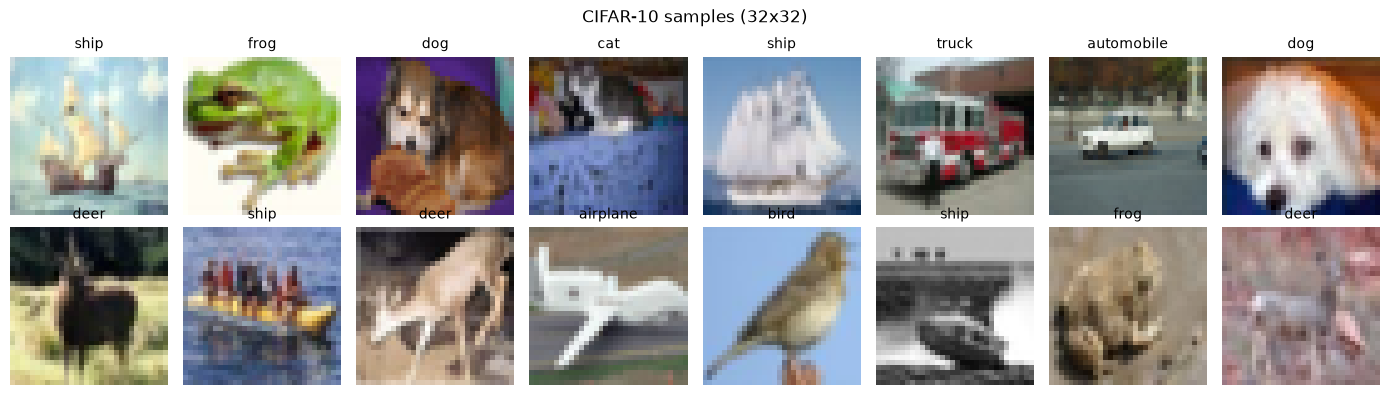

In [4]:
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, idx in zip(axes.flatten(), np.random.choice(len(cifar_train_raw), 16, replace=False)):
    img, label = cifar_train_raw[idx]
    ax.imshow(img)
    ax.set_title(CIFAR_CLASSES[label], fontsize=10)
    ax.axis("off")
plt.suptitle("CIFAR-10 samples (32x32)")
plt.tight_layout()
plt.show()

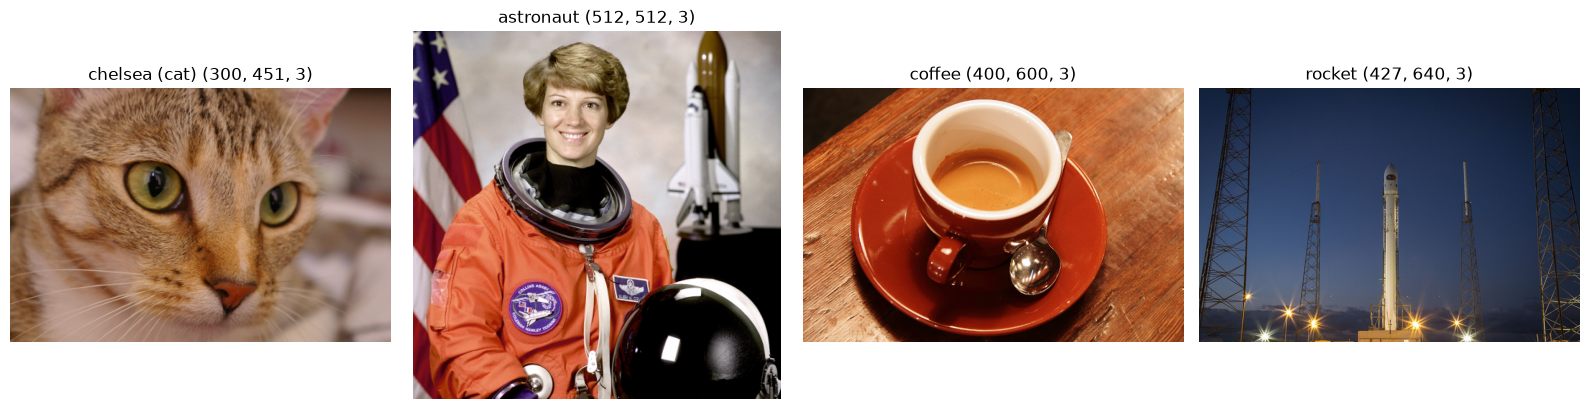

In [5]:
# A few natural "large" images for visualizations
natural_images = {
    "chelsea (cat)": skdata.chelsea(),
    "astronaut": skdata.astronaut(),
    "coffee": skdata.coffee(),
    "rocket": skdata.rocket(),
}

fig, axes = plt.subplots(1, len(natural_images), figsize=(16, 4))
for ax, (name, img) in zip(axes, natural_images.items()):
    ax.imshow(img)
    ax.set_title(f"{name} {img.shape}")
    ax.axis("off")
plt.tight_layout()
plt.show()

<a id='Patch_Embedding'></a>
# Patch Embedding: an image is worth 16x16 words

## Step 1: Image $\rightarrow$ sequence of patches

A Transformer consumes a **sequence of vectors**. An image $\mathbf{x} \in \mathbb{R}^{H \times W \times C}$ is reshaped into a sequence of flattened patches

$$
\mathbf{x}_p \in \mathbb{R}^{N \times (P^2 \cdot C)}, \qquad N = \frac{H \cdot W}{P^2}.
$$

For $224 \times 224$ images and $P=16$: $N = 14 \times 14 = 196$ tokens, each of dimension $16 \cdot 16 \cdot 3 = 768$.

**Why not pixels as tokens?** Self-attention costs $\mathcal{O}(N^2)$. With pixels $N = 50{,}176$ and the attention matrix of a single head would have $2.5 \cdot 10^9$ entries (10 GB in fp32) — per layer, per image. Patches are a crude but effective way to shorten the sequence.

Let's implement "patchify" with `einops` — it is just a reshape, no learnable parameters.

In [6]:
def patchify(images: torch.Tensor, patch_size: int) -> torch.Tensor:
    """(B, C, H, W) -> (B, N, P*P*C)"""
    return rearrange(images, "b c (h p1) (w p2) -> b (h w) (p1 p2 c)", p1=patch_size, p2=patch_size)


def unpatchify(patches: torch.Tensor, patch_size: int, channels: int = 3) -> torch.Tensor:
    """(B, N, P*P*C) -> (B, C, H, W), assumes a square grid"""
    grid = int(math.sqrt(patches.shape[1]))
    return rearrange(
        patches, "b (h w) (p1 p2 c) -> b c (h p1) (w p2)", h=grid, w=grid, p1=patch_size, p2=patch_size, c=channels
    )


cat = torch.from_numpy(skdata.chelsea()).permute(2, 0, 1).float() / 255.0
cat = F.interpolate(cat[None], size=(224, 224), mode="bilinear", antialias=True)
patches = patchify(cat, patch_size=16)
print("image:", tuple(cat.shape), "-> patches:", tuple(patches.shape))
assert torch.equal(unpatchify(patches, 16), cat), "patchify must be invertible"

image: (1, 3, 224, 224) -> patches: (1, 196, 768)


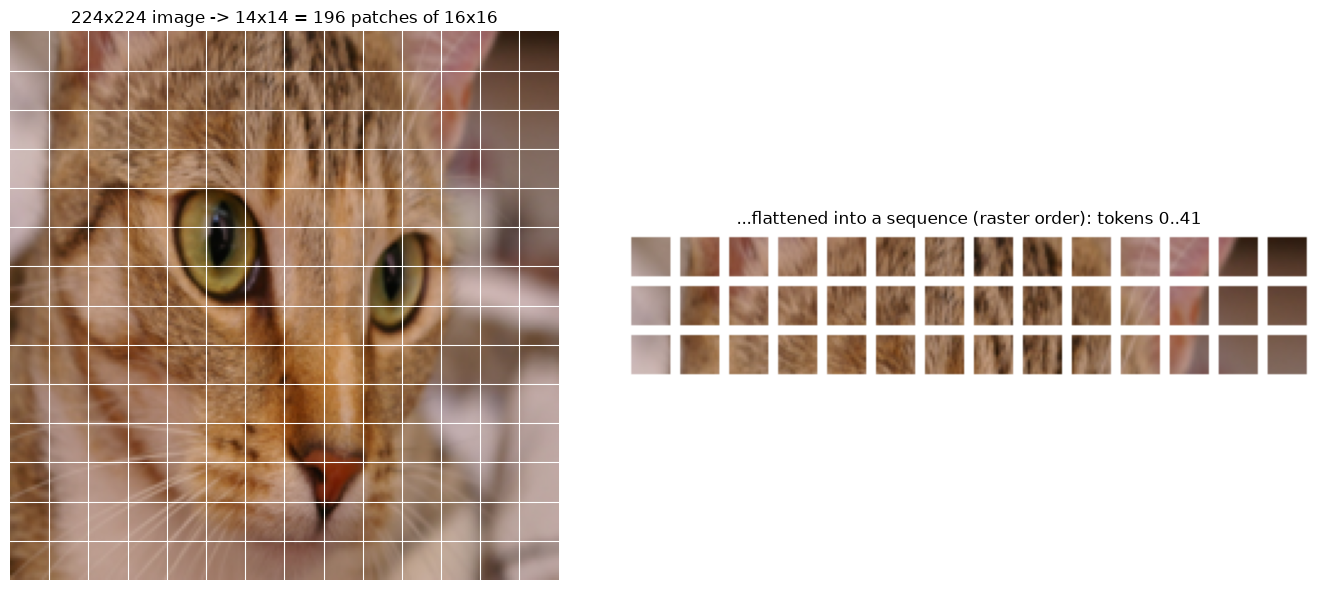

In [7]:
P = 16
grid = 224 // P
fig = plt.figure(figsize=(14, 6))

ax = fig.add_subplot(1, 2, 1)
ax.imshow(cat[0].permute(1, 2, 0))
for i in range(1, grid):
    ax.axhline(i * P - 0.5, color="white", lw=0.8)
    ax.axvline(i * P - 0.5, color="white", lw=0.8)
ax.set_title(f"224x224 image -> {grid}x{grid} = {grid * grid} patches of {P}x{P}")
ax.axis("off")

# The same patches laid out as a *sequence* (raster order), first 42 of them
ax = fig.add_subplot(1, 2, 2)
seq = patches[0, :42].reshape(42, P, P, 3)
strip = torch.ones(3, P + 4, 14 * (P + 4), 3)
for i in range(42):
    r, c = divmod(i, 14)
    strip[r, 2:P + 2, c * (P + 4) + 2:c * (P + 4) + P + 2] = seq[i]
ax.imshow(rearrange(strip, "r h w c -> (r h) w c"))
ax.set_title("...flattened into a sequence (raster order): tokens 0..41")
ax.axis("off")
plt.tight_layout()
plt.show()

## Step 2: Linear projection

Each flattened patch $\mathbf{x}_p^i \in \mathbb{R}^{P^2 C}$ is mapped to a $D$-dimensional token with a **shared** learnable matrix:

$$
\mathbf{z}^i = \mathbf{x}_p^i \mathbf{E} + \mathbf{b}, \qquad \mathbf{E} \in \mathbb{R}^{(P^2 C) \times D}.
$$

This is the visual analogue of a word-embedding lookup table: a continuous "vocabulary" of patches.

### Key observation: patch embedding **is** a convolution

A linear layer applied to non-overlapping $P \times P$ patches is exactly a `Conv2d` with `kernel_size = stride = P` and `D` output channels. Every implementation (`timm`, the original JAX code, HF `transformers`) uses the convolution because it is faster and avoids an explicit reshape. Let's **prove** it numerically by copying the weights from one to the other.

In [8]:
P, D = 16, 192
linear = nn.Linear(P * P * 3, D)
conv = nn.Conv2d(3, D, kernel_size=P, stride=P)

with torch.no_grad():
    # Linear weight is (D, P*P*C) in (p1 p2 c) order -> conv weight is (D, C, P, P)
    conv.weight.copy_(rearrange(linear.weight, "d (p1 p2 c) -> d c p1 p2", p1=P, p2=P))
    conv.bias.copy_(linear.bias)

x = torch.randn(4, 3, 224, 224)
out_linear = linear(patchify(x, P))                          # (B, N, D)
out_conv = rearrange(conv(x), "b d h w -> b (h w) d")        # (B, N, D)

print("linear:", tuple(out_linear.shape), "| conv:", tuple(out_conv.shape))
print("max abs difference:", (out_linear - out_conv).abs().max().item())

linear: (4, 196, 192) | conv: (4, 196, 192)
max abs difference: 2.7418136596679688e-06


In [9]:
class PatchEmbed(nn.Module):
    """Image -> sequence of patch tokens. (B, C, H, W) -> (B, N, D)"""

    def __init__(self, img_size=224, patch_size=16, in_chans=3, embed_dim=768):
        super().__init__()
        assert img_size % patch_size == 0, "image size must be divisible by the patch size"
        self.img_size = img_size
        self.patch_size = patch_size
        self.grid_size = img_size // patch_size
        self.num_patches = self.grid_size ** 2
        self.proj = nn.Conv2d(in_chans, embed_dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, x):
        x = self.proj(x)                        # (B, D, H/P, W/P)
        return x.flatten(2).transpose(1, 2)     # (B, N, D)


patch_embed = PatchEmbed(img_size=224, patch_size=16, embed_dim=768)
print(tuple(patch_embed(torch.randn(2, 3, 224, 224)).shape))

(2, 196, 768)


## Patch size is the most important "hidden" hyperparameter

The patch size controls the sequence length, and the sequence length controls the compute:

* smaller patches $\Rightarrow$ finer details, **more tokens** $\Rightarrow$ quadratically more expensive attention;
* the number of parameters **does not** depend on the resolution (only $\mathbf{E}_{pos}$ does), so the same model can be run at different resolutions — a big difference from the fixed-size flatten+FC heads of old CNNs.

A quick back-of-the-envelope table (one head, fp16 attention matrix):

In [10]:
rows = []
for res in [32, 224, 384, 512, 1024]:
    for p in [4, 8, 14, 16, 32]:
        if res % p != 0 or (res == 32 and p > 8) or (res > 32 and p < 8):
            continue
        n = (res // p) ** 2
        rows.append({
            "resolution": res,
            "patch": p,
            "tokens N": n,
            "attn entries N^2": f"{n * n:,}",
            "attn matrix / head / layer (fp16)": f"{n * n * 2 / 2**20:.2f} MB",
        })
pd.DataFrame(rows)

,resolution,patch,tokens N,attn entries N^2,attn matrix / head / layer (fp16)
0,32,4,64,"4,096",0.01 MB
1,32,8,16,256,0.00 MB
2,224,8,784,"614,656",1.17 MB
3,224,14,256,"65,536",0.12 MB
4,224,16,196,"38,416",0.07 MB
5,224,32,49,"2,401",0.00 MB
6,384,8,2304,"5,308,416",10.12 MB
7,384,16,576,"331,776",0.63 MB
8,384,32,144,"20,736",0.04 MB
9,512,8,4096,"16,777,216",32.00 MB


Notice how CIFAR-10 at $32 \times 32$ with $P = 4$ gives the same **64 tokens** as a $256 \times 256$ image with $P = 32$. For CIFAR we will use $P=4$: with $P=16$ we would get only $2 \times 2 = 4$ tokens, which is far too coarse.

In practice, patch size is also a compute knob in **scaling laws**: at a fixed model size, smaller patches (= more tokens) consistently improve accuracy, at quadratic attention cost (Zhai et al., *Scaling Vision Transformers*, 2022). Modern foundation encoders live in the "many tokens" regime: DINOv2 uses $P=14$ at $518 \times 518$ ($N = 1369$), DINOv3 switched to $P = 16$ and adapts to 512–768 px, and SAM uses $P=16$ at $1024 \times 1024$ ($N = 4096$). Handling that many tokens efficiently is one of the topics of the next lecture.

<a id='Self_Attention'></a>
# Self-Attention and Multi-Head Self-Attention

## Scaled dot-product attention

Given a sequence of tokens $\mathbf{X} \in \mathbb{R}^{N \times D}$ we compute three projections:

$$
\mathbf{Q} = \mathbf{X}\mathbf{W}_Q, \quad \mathbf{K} = \mathbf{X}\mathbf{W}_K, \quad \mathbf{V} = \mathbf{X}\mathbf{W}_V, \qquad \mathbf{W}_{Q,K,V} \in \mathbb{R}^{D \times d}
$$

* **Query** — "what am I looking for?"
* **Key** — "what do I contain?"
* **Value** — "what will I give you if you attend to me?"

and then

$$
\mathrm{Attention}(\mathbf{Q},\mathbf{K},\mathbf{V}) = \underbrace{\mathrm{softmax}\!\left(\frac{\mathbf{Q}\mathbf{K}^\top}{\sqrt{d}}\right)}_{\mathbf{A} \in \mathbb{R}^{N \times N}} \mathbf{V}.
$$

Row $i$ of $\mathbf{A}$ is a probability distribution telling how much token $i$ takes from every other token. The output for token $i$ is a **data-dependent weighted average** of all values — compare with a convolution, where the weights of the average are fixed and non-zero only in a small window.

## Why divide by $\sqrt{d}$?

If the entries of $\mathbf{q}$ and $\mathbf{k}$ are i.i.d. with zero mean and unit variance, then

$$
\mathrm{Var}(\mathbf{q}^\top \mathbf{k}) = \sum_{j=1}^{d} \mathrm{Var}(q_j k_j) = d.
$$

The logits grow like $\sqrt{d}$, softmax **saturates** into an almost one-hot distribution, and its gradient $\partial\, \mathrm{softmax} / \partial\, \text{logits} = \mathrm{diag}(\mathbf{a}) - \mathbf{a}\mathbf{a}^\top$ vanishes. Dividing by $\sqrt{d}$ restores unit variance. Let's check it empirically.

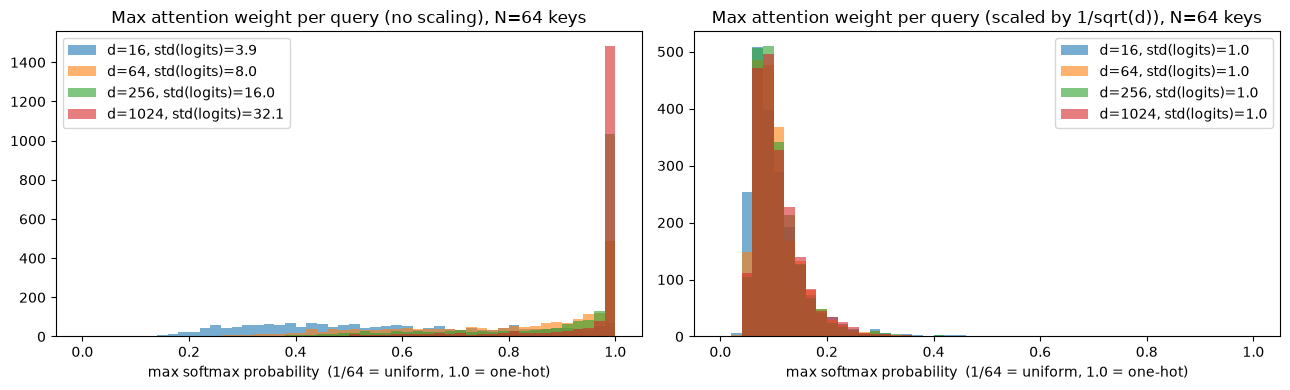

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for d in [16, 64, 256, 1024]:
    q, k = torch.randn(2000, d), torch.randn(64, d)
    logits = q @ k.T
    for ax, scale, name in [(axes[0], 1.0, "no scaling"), (axes[1], d ** -0.5, "scaled by 1/sqrt(d)")]:
        max_prob = (logits * scale).softmax(-1).max(-1).values
        ax.hist(max_prob.numpy(), bins=50, range=(0, 1), alpha=0.6, label=f"d={d}, std(logits)={(logits * scale).std():.1f}")
        ax.set_title(f"Max attention weight per query ({name}), N=64 keys")
        ax.set_xlabel("max softmax probability  (1/64 = uniform, 1.0 = one-hot)")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

Without scaling, attention with realistic head dimensions ($d = 64$) becomes nearly one-hot at initialization, which kills gradient flow. With scaling the distribution stays soft regardless of $d$.

## Implementation from scratch

Shapes convention used everywhere below: `(B, h, N, d)` — batch, heads, tokens, head dimension.

In [12]:
def attention(q, k, v, return_attn=False):
    """Naive scaled dot-product attention. q, k, v: (B, h, N, d)"""
    scale = q.shape[-1] ** -0.5
    attn = (q @ k.transpose(-2, -1)) * scale     # (B, h, N, N)
    attn = attn.softmax(dim=-1)
    out = attn @ v                               # (B, h, N, d)
    return (out, attn) if return_attn else out


q, k, v = torch.randn(3, 2, 4, 197, 64).unbind(0)
out_naive, attn = attention(q, k, v, return_attn=True)
out_torch = F.scaled_dot_product_attention(q, k, v)

print("output:", tuple(out_naive.shape), "| attention matrix:", tuple(attn.shape))
print("rows sum to 1:", torch.allclose(attn.sum(-1), torch.ones(1)))
print("max diff vs F.scaled_dot_product_attention:", (out_naive - out_torch).abs().max().item())

output: (2, 4, 197, 64) | attention matrix: (2, 4, 197, 197)
rows sum to 1: True
max diff vs F.scaled_dot_product_attention: 4.76837158203125e-07


## Multi-Head Self-Attention (MHSA)

A single softmax can only express **one** "kind" of relation per token. MHSA runs $h$ attentions in parallel, each in its own subspace of dimension $d = D / h$, and concatenates the results:

$$
\mathrm{MSA}(\mathbf{X}) = [\mathrm{head}_1; \dots; \mathrm{head}_h]\, \mathbf{W}_O, \qquad \mathrm{head}_i = \mathrm{Attention}(\mathbf{X}\mathbf{W}_Q^i, \mathbf{X}\mathbf{W}_K^i, \mathbf{X}\mathbf{W}_V^i).
$$

The cost of MHSA is the same as single-head attention with dimension $D$: we do not add parameters, we only **split** the channels. In practice all $3h$ projections are fused into a single `Linear(D, 3D)` (called `qkv`) for efficiency.

We name the modules exactly like `timm` does (`qkv`, `proj`) — later this will allow us to load pretrained weights into our own implementation. We also add a switch to keep the attention maps for visualization; otherwise we call the fused `F.scaled_dot_product_attention` kernel (FlashAttention / memory-efficient attention under the hood).

In [13]:
class Attention(nn.Module):
    def __init__(self, dim, num_heads=8, qkv_bias=True, attn_drop=0.0, proj_drop=0.0):
        super().__init__()
        assert dim % num_heads == 0, "dim must be divisible by num_heads"
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.scale = self.head_dim ** -0.5

        self.qkv = nn.Linear(dim, dim * 3, bias=qkv_bias)
        self.attn_drop = nn.Dropout(attn_drop)
        self.proj = nn.Linear(dim, dim)
        self.proj_drop = nn.Dropout(proj_drop)

        # Visualization helpers: if True, compute attention explicitly and keep the map
        self.store_attn = False
        self.attn_map = None

    def forward(self, x):
        B, N, C = x.shape
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv.unbind(0)                                  # each (B, h, N, d)

        if self.store_attn:
            attn = ((q @ k.transpose(-2, -1)) * self.scale).softmax(dim=-1)
            self.attn_map = attn.detach()
            x = self.attn_drop(attn) @ v
        else:
            x = F.scaled_dot_product_attention(q, k, v, dropout_p=self.attn_drop.p if self.training else 0.0)

        x = x.transpose(1, 2).reshape(B, N, C)                   # concat heads
        return self.proj_drop(self.proj(x))


mhsa = Attention(dim=384, num_heads=6)
tokens = torch.randn(2, 197, 384)
print("MHSA:", tuple(tokens.shape), "->", tuple(mhsa(tokens).shape))
count_params(mhsa);

MHSA: (2, 197, 384) -> (2, 197, 384)
Total params:     0.59M
Trainable params: 0.59M


## The price of global attention: $\mathcal{O}(N^2)$

Per layer, MHSA costs $4ND^2$ multiply-accumulates (MACs) for the $\mathbf{Q}, \mathbf{K}, \mathbf{V}$ and output projections plus $2N^2D$ MACs for $\mathbf{Q}\mathbf{K}^\top$ and $\mathbf{A}\mathbf{V}$ (1 MAC = 2 FLOPs). Adding the MLP ($2 \cdot N \cdot D \cdot 4D = 8ND^2$), a full transformer block costs

$$
\text{MACs}_{\text{block}} \approx 12ND^2 + 2N^2D .
$$

The quadratic term dominates as soon as $N > 6D$ — e.g. for ViT-B ($D = 768$) beyond $\sim 4600$ tokens, i.e. $\gtrsim 1088 \times 1088$ images with $P = 16$. The naive implementation additionally has to **store** the $N \times N$ matrix for every head.

Let's measure the naive attention vs the fused PyTorch kernel on our device.

In [14]:
rows = []
h, d = 6, 64
# the naive version materializes (h, N, N) matrices -> keep N moderate outside of a CUDA GPU
for n in [256, 1024, 2048, 4096, 8192] if DEVICE == "cuda" else [256, 1024, 2048, 4096]:
    q, k, v = torch.randn(3, 1, h, n, d, device=DEVICE).unbind(0)
    row = {"N": n, "attn matrix (fp32, all heads)": f"{h * n * n * 4 / 2**20:.0f} MB"}
    row["naive, ms"] = benchmark_fn(lambda: attention(q, k, v), DEVICE)
    row["F.scaled_dot_product_attention, ms"] = benchmark_fn(lambda: F.scaled_dot_product_attention(q, k, v), DEVICE)
    rows.append(row)
attn_bench = pd.DataFrame(rows)
attn_bench

,N,"attn matrix (fp32, all heads)","naive, ms","F.scaled_dot_product_attention, ms"
0,256,2 MB,0.082905,0.030934
1,1024,24 MB,0.087706,0.106879
2,2048,96 MB,0.474187,0.344331
3,4096,384 MB,1.823547,1.080850
4,8192,1536 MB,7.186854,3.331286


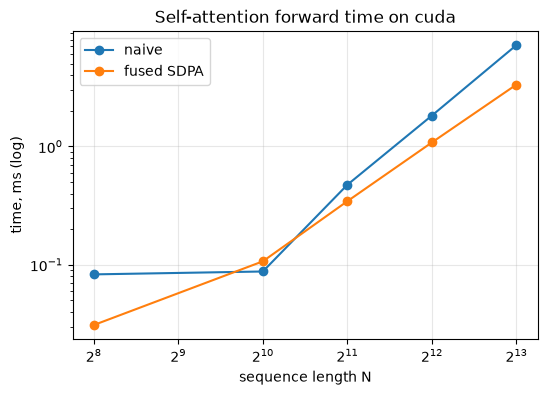

In [15]:
plt.figure(figsize=(6, 4))
plt.plot(attn_bench["N"], attn_bench["naive, ms"], marker="o", label="naive")
plt.plot(attn_bench["N"], attn_bench["F.scaled_dot_product_attention, ms"], marker="o", label="fused SDPA")
plt.xscale("log", base=2)
plt.yscale("log")
plt.xlabel("sequence length N")
plt.ylabel("time, ms (log)")
plt.title(f"Self-attention forward time on {DEVICE}")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

Both curves grow roughly quadratically: a fused kernel removes the **memory** bottleneck (never materializes $\mathbf{A}$ in slow memory) and is faster, but it does **not** change the $\mathcal{O}(N^2)$ compute. Reducing that is one of the main themes of the next lecture (windows, hierarchies, token merging).

<a id='Transformer_Block'></a>
# Transformer Block

A ViT encoder block is exactly the Transformer encoder block from NLP, in its **pre-norm** form:

$$
\begin{aligned}
\mathbf{x} &\leftarrow \mathbf{x} + \mathrm{DropPath}\big(\mathrm{MSA}(\mathrm{LN}(\mathbf{x}))\big) \\
\mathbf{x} &\leftarrow \mathbf{x} + \mathrm{DropPath}\big(\mathrm{MLP}(\mathrm{LN}(\mathbf{x}))\big)
\end{aligned}
$$

## Components

**MLP (a.k.a. FFN).** Two linear layers with GELU in between and hidden size $4D$ (`mlp_ratio = 4`). Attention *mixes information between tokens*; the MLP *processes every token independently* (it is a $1 \times 1$ convolution in CNN language). About $2/3$ of ViT parameters live in the MLPs.

**LayerNorm, not BatchNorm.** LN normalizes every token over its $D$ channels:
$\mathrm{LN}(\mathbf{x}) = \gamma \odot \frac{\mathbf{x} - \mu(\mathbf{x})}{\sigma(\mathbf{x})} + \beta$. It does not depend on the batch (no train/eval discrepancy, works with batch size 1 and with variable sequence lengths).

**Residual connections** make the block a small *correction* to the identity, allowing very deep stacks.

**Pre-norm vs post-norm.** The original Transformer used $\mathrm{LN}(\mathbf{x} + \mathrm{F}(\mathbf{x}))$ (post-norm). In post-norm every residual branch passes through LayerNorm, so the gradient to early layers is repeatedly rescaled; deep post-norm models need learning-rate warmup and careful tuning to train at all. In pre-norm the residual stream is an **uninterrupted identity path** from input to output.

**DropPath (stochastic depth).** During training, the entire residual branch is dropped for a random subset of samples: $\mathbf{x} + \frac{m}{1-p}\,\mathrm{F}(\mathbf{x})$, $m \sim \mathrm{Bernoulli}(1-p)$. The drop probability grows linearly with depth. It is one of the most important regularizers for ViTs trained on moderate data.

In [16]:
class Mlp(nn.Module):
    def __init__(self, in_features, hidden_features, drop=0.0):
        super().__init__()
        self.fc1 = nn.Linear(in_features, hidden_features)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(hidden_features, in_features)
        self.drop = nn.Dropout(drop)

    def forward(self, x):
        return self.drop(self.fc2(self.drop(self.act(self.fc1(x)))))


class DropPath(nn.Module):
    """Stochastic depth: drop the whole residual branch per sample."""

    def __init__(self, drop_prob=0.0):
        super().__init__()
        self.drop_prob = drop_prob

    def forward(self, x):
        if self.drop_prob == 0.0 or not self.training:
            return x
        keep_prob = 1 - self.drop_prob
        mask = x.new_empty((x.shape[0],) + (1,) * (x.ndim - 1)).bernoulli_(keep_prob)
        return x * mask / keep_prob


class Block(nn.Module):
    def __init__(self, dim, num_heads, mlp_ratio=4.0, qkv_bias=True, drop=0.0, attn_drop=0.0, drop_path=0.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim, eps=1e-6)
        self.attn = Attention(dim, num_heads=num_heads, qkv_bias=qkv_bias, attn_drop=attn_drop, proj_drop=drop)
        self.drop_path = DropPath(drop_path)
        self.norm2 = nn.LayerNorm(dim, eps=1e-6)
        self.mlp = Mlp(dim, int(dim * mlp_ratio), drop=drop)

    def forward(self, x):
        x = x + self.drop_path(self.attn(self.norm1(x)))
        x = x + self.drop_path(self.mlp(self.norm2(x)))
        return x


block = Block(dim=384, num_heads=6)
print("Block:", tuple(tokens.shape), "->", tuple(block(tokens).shape))
n_attn = sum(p.numel() for p in block.attn.parameters())
n_mlp = sum(p.numel() for p in block.mlp.parameters())
print(f"attention params: {n_attn:,} | MLP params: {n_mlp:,} ({n_mlp / (n_attn + n_mlp):.0%} of the block)")

Block: (2, 197, 384) -> (2, 197, 384)
attention params: 591,360 | MLP params: 1,181,568 (67% of the block)


### Experiment: why pre-norm? Training without warmup

The classic failure mode of post-norm transformers (Xiong et al., 2020): at the beginning of training the gradients of the parameters close to the output are large, so with a normal learning rate and **no warmup** the optimization blows up. We train a 12-block ViT on 20k CIFAR-10 images for 600 steps, pre-norm vs post-norm, with and without a 200-step linear warmup. Everything else (init, optimizer, data order) is identical.

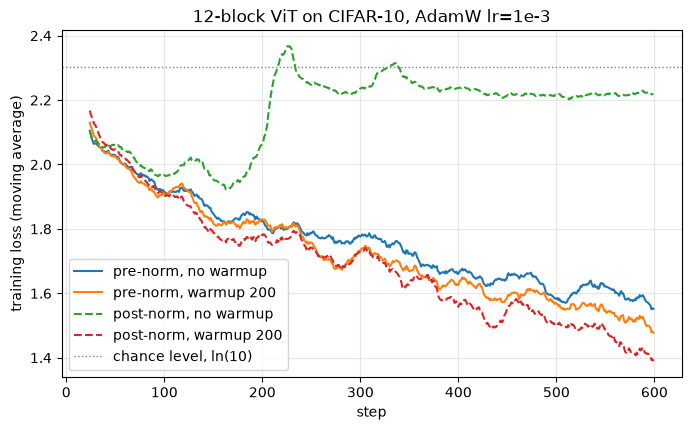

In [17]:
class PostNormBlock(Block):
    # The original Transformer layout: LN(x + F(x))
    def forward(self, x):
        x = self.norm1(x + self.attn(x))
        x = self.norm2(x + self.mlp(x))
        return x


class MiniViT(nn.Module):
    # Patch embedding + learned positions + a stack of blocks + GAP head (for 32x32 inputs)
    def __init__(self, block_cls, depth=12, dim=192, heads=3, num_classes=10):
        super().__init__()
        self.patch_embed = PatchEmbed(img_size=32, patch_size=4, embed_dim=dim)
        self.pos_embed = nn.Parameter(torch.randn(1, self.patch_embed.num_patches, dim) * 0.02)
        self.blocks = nn.Sequential(*[block_cls(dim, heads) for _ in range(depth)])
        self.norm = nn.LayerNorm(dim, eps=1e-6)
        self.head = nn.Linear(dim, num_classes)
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.trunc_normal_(m.weight, std=0.02)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.blocks(self.patch_embed(x) + self.pos_embed)
        return self.head(self.norm(x).mean(dim=1))


def short_training_run(block_cls, warmup_steps, steps=600, lr=1e-3, batch_size=128, n_images=20000, seed=0):
    torch.manual_seed(seed)
    X = torch.from_numpy(cifar_train_raw.data[:n_images]).permute(0, 3, 1, 2).float().div(255).sub(0.5).div(0.25)
    Y = torch.tensor(cifar_train_raw.targets[:n_images])
    X, Y = X.to(DEVICE), Y.to(DEVICE)
    model = MiniViT(block_cls).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.05)
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda step: min(1.0, (step + 1) / warmup_steps) if warmup_steps else 1.0
    )
    losses = []
    for _ in range(steps):
        idx = torch.randint(0, n_images, (batch_size,), device=DEVICE)
        with torch.autocast(DEVICE, dtype=torch.bfloat16, enabled=DEVICE in ("cuda", "mps")):
            loss = F.cross_entropy(model(X[idx]), Y[idx])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()
        losses.append(loss.item())
    return losses


norm_path = os.path.join(RESULTS_DIR, "prenorm_vs_postnorm.csv")
if RUN_EXPERIMENTS:
    norm_runs = pd.DataFrame({
        f"{name}, {'warmup 200' if warmup else 'no warmup'}": short_training_run(block_cls, warmup)
        for name, block_cls in [("pre-norm", Block), ("post-norm", PostNormBlock)]
        for warmup in [0, 200]
    })
    norm_runs.to_csv(norm_path, index_label="step")
else:
    norm_runs = pd.read_csv(norm_path, index_col="step")

plt.figure(figsize=(8, 4.5))
for col in norm_runs.columns:
    plt.plot(norm_runs[col].rolling(25).mean(), label=col, ls="-" if "pre" in col else "--")
plt.axhline(math.log(10), color="gray", lw=1, ls=":", label="chance level, ln(10)")
plt.xlabel("step"); plt.ylabel("training loss (moving average)")
plt.title("12-block ViT on CIFAR-10, AdamW lr=1e-3")
plt.grid(alpha=0.3); plt.legend()
plt.show()

Without warmup, the **post-norm** model starts learning, then its loss climbs back towards the chance level $\ln 10 \approx 2.30$ after ~200 steps and does not recover. With a 200-step warmup the *same* model trains fine — in this 12-block setting it even ends up slightly ahead of pre-norm. The **pre-norm** model trains in both settings: its residual stream is an uninterrupted identity path, so the updates at the start of training stay bounded.

So the advantage of pre-norm is **robustness** of optimization (to warmup, learning rate and depth), not necessarily better final accuracy — which is exactly what matters when you train large models where every failed run is expensive. This is why all modern vision transformers are pre-norm, and why warmup is still part of every ViT recipe (it helps pre-norm too).

> A side remark: if you measure only *gradient norms at initialization* with the ViT init (std 0.02), pre- and post-norm look almost identical, because every residual branch is tiny and both stacks are close to the identity. The difference shows up in the **training dynamics**, which is why we train here.

<a id='Positional_Embeddings'></a>
# Order Matters: CLS token and Positional Embeddings

## Transformers see a *bag* of patches

Self-attention and the MLP are **permutation-equivariant**: if we shuffle the input tokens, the outputs are shuffled in exactly the same way,

$$
f(\Pi \mathbf{X}) = \Pi f(\mathbf{X}) \quad \text{for any permutation matrix } \Pi.
$$

Consequently, any pooled output (e.g. the mean over tokens) is **permutation-invariant**: the model cannot distinguish an image from a "jigsaw-shuffled" version of it. Let's verify with our own blocks.

equivariance: f(shuffle(x)) == shuffle(f(x)) -> True
invariance of mean-pooled output -> True


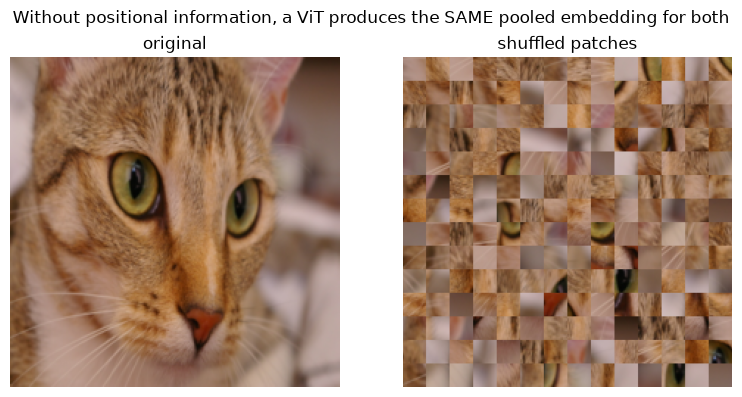

In [18]:
torch.manual_seed(0)
encoder = nn.Sequential(*[Block(dim=192, num_heads=3) for _ in range(4)]).eval()
patch_embed_small = PatchEmbed(img_size=224, patch_size=16, embed_dim=192)

with torch.no_grad():
    tokens = patch_embed_small(cat)                       # (1, 196, 192)
    perm = torch.randperm(tokens.shape[1])
    out = encoder(tokens)
    out_shuffled = encoder(tokens[:, perm])

print("equivariance: f(shuffle(x)) == shuffle(f(x)) ->", torch.allclose(out_shuffled, out[:, perm], atol=1e-5))
print("invariance of mean-pooled output ->", torch.allclose(out.mean(1), out_shuffled.mean(1), atol=1e-5))

shuffled_img = unpatchify(patches[:, perm], 16)
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(cat[0].permute(1, 2, 0)); axes[0].set_title("original")
axes[1].imshow(shuffled_img[0].permute(1, 2, 0)); axes[1].set_title("shuffled patches")
for ax in axes:
    ax.axis("off")
plt.suptitle("Without positional information, a ViT produces the SAME pooled embedding for both")
plt.tight_layout()
plt.show()

## Positional embeddings

To break the symmetry we add a position-dependent vector to every token: $\mathbf{z}_0 = \mathbf{X}\mathbf{E} + \mathbf{E}_{pos}$.

| Variant | Formula / idea | Used in |
|---|---|---|
| **Learned absolute 1D** | $\mathbf{E}_{pos} \in \mathbb{R}^{(N+1) \times D}$ is just a parameter | ViT, DeiT, CLIP, DINOv2 |
| **Fixed 2D sin-cos** | half of the channels encode the row, half the column, with sinusoids of different frequencies | MAE, "Better plain ViT baselines" |
| **Relative position bias** | a learned bias $B_{i-j}$ is added to the attention logits | Swin, BEiT |
| **Conditional (PEG)** | positions generated on the fly by a depthwise conv | CPVT, PVTv2 |
| **RoPE-2D** | rotate $\mathbf{q}, \mathbf{k}$ by angles proportional to the 2D position | EVA-02, DINOv3 |

The ViT paper found that 1D learned embeddings work as well as 2D-aware ones — the model **learns the 2D structure by itself** (we will see this below). The last three variants will be covered in the next lecture.

### 2D sin-cos embeddings from scratch

For a token at grid position $(r, c)$ and frequencies $\omega_k = 10000^{-k/(D/4)}$, $k = 0 \dots D/4 - 1$:

$$
\mathbf{p}_{(r,c)} = \big[\sin(c\,\omega),\ \cos(c\,\omega),\ \sin(r\,\omega),\ \cos(r\,\omega)\big] \in \mathbb{R}^D.
$$

The dot product $\mathbf{p}_{(r,c)}^\top \mathbf{p}_{(r',c')}$ depends only on the offsets $(r - r', c - c')$, which gives a smooth notion of distance.

sin-cos pos embed: (196, 384)


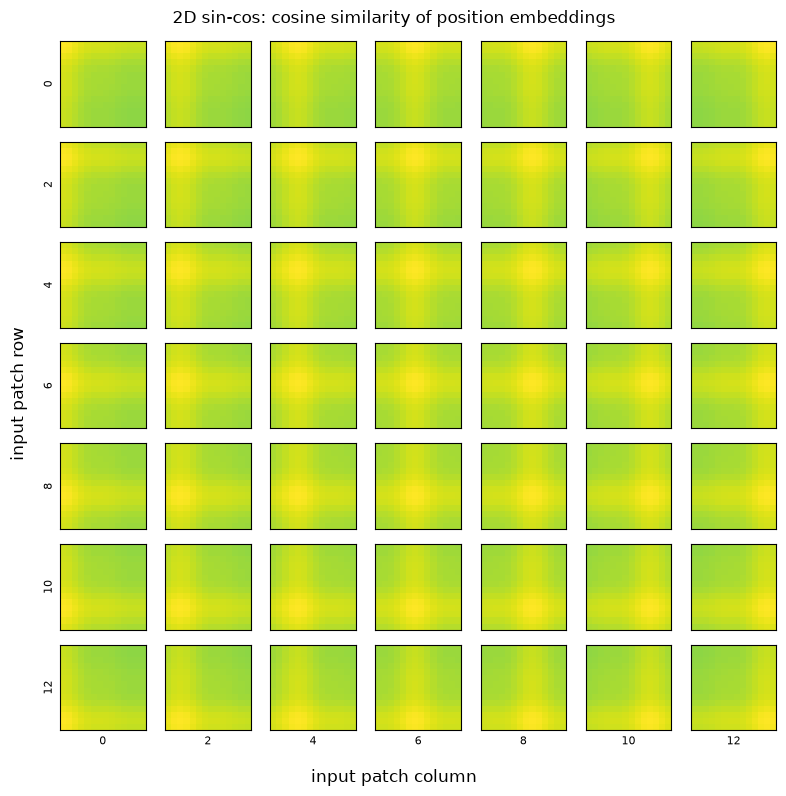

In [19]:
def get_2d_sincos_pos_embed(embed_dim: int, grid_size: int, temperature: float = 10000.0) -> torch.Tensor:
    """Returns (grid_size**2, embed_dim) fixed positional embeddings in raster order."""
    assert embed_dim % 4 == 0, "embed_dim must be divisible by 4 for 2D sin-cos embeddings"
    rows, cols = torch.meshgrid(torch.arange(grid_size), torch.arange(grid_size), indexing="ij")
    omega = 1.0 / temperature ** (torch.arange(embed_dim // 4) / (embed_dim // 4))
    r = rows.flatten()[:, None].float() * omega[None]
    c = cols.flatten()[:, None].float() * omega[None]
    return torch.cat([c.sin(), c.cos(), r.sin(), r.cos()], dim=1)


def plot_pos_embed_similarity(pos_embed: torch.Tensor, grid_size: int, title: str, step: int = 1):
    """For every (sub-sampled) position, plot the cosine similarity of its embedding to all other positions."""
    sim = F.cosine_similarity(pos_embed[:, None], pos_embed[None], dim=-1)   # (N, N)
    positions = list(range(0, grid_size, step))
    fig, axes = plt.subplots(len(positions), len(positions), figsize=(8, 8))
    for i, r in enumerate(positions):
        for j, c in enumerate(positions):
            axes[i, j].imshow(sim[r * grid_size + c].reshape(grid_size, grid_size), cmap="viridis", vmin=-1, vmax=1)
            axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
            if j == 0: axes[i, j].set_ylabel(r, fontsize=8)
            if i == len(positions) - 1: axes[i, j].set_xlabel(c, fontsize=8)
    fig.supylabel("input patch row"); fig.supxlabel("input patch column")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


sincos = get_2d_sincos_pos_embed(embed_dim=384, grid_size=14)
print("sin-cos pos embed:", tuple(sincos.shape))
plot_pos_embed_similarity(sincos, grid_size=14, title="2D sin-cos: cosine similarity of position embeddings", step=2)

## Changing the resolution: interpolating positional embeddings

Weights of the patch embedding and the blocks are resolution-agnostic, but a learned $\mathbf{E}_{pos}$ has exactly $N+1$ rows. To fine-tune or run a model at a different resolution (very common: pre-train at 224, fine-tune at 384) we reshape $\mathbf{E}_{pos}$ back into its 2D grid and **resize it like an image** (bicubic interpolation). Prefix tokens such as [CLS] are kept untouched.

In [20]:
def resample_pos_embed(pos_embed: torch.Tensor, new_grid: int, num_prefix_tokens: int = 1) -> torch.Tensor:
    """(1, prefix + old_grid**2, D) -> (1, prefix + new_grid**2, D)"""
    prefix, grid_tokens = pos_embed[:, :num_prefix_tokens], pos_embed[:, num_prefix_tokens:]
    old_grid = int(math.sqrt(grid_tokens.shape[1]))
    grid_tokens = rearrange(grid_tokens, "1 (h w) d -> 1 d h w", h=old_grid, w=old_grid)
    grid_tokens = F.interpolate(grid_tokens, size=(new_grid, new_grid), mode="bicubic", align_corners=False)
    grid_tokens = rearrange(grid_tokens, "1 d h w -> 1 (h w) d")
    return torch.cat([prefix, grid_tokens], dim=1)


pe = torch.randn(1, 1 + 14 * 14, 384)
for g in [7, 24, 32]:
    print(f"14x14 -> {g}x{g}:", tuple(resample_pos_embed(pe, g).shape))

14x14 -> 7x7: (1, 50, 384)
14x14 -> 24x24: (1, 577, 384)
14x14 -> 32x32: (1, 1025, 384)


## The [CLS] token vs Global Average Pooling

ViT (following BERT) prepends a learnable token $\mathbf{x}_{\text{cls}}$ with no image content. Through attention it aggregates information from all patches, and its final state is used as the image representation.

The alternative is **global average pooling (GAP)** of the patch tokens — the CNN way. Both work; GAP is often slightly better/more stable when training from scratch (it was adopted by "Better plain ViT baselines" and many hierarchical models that have no [CLS] at all), while [CLS] is standard in pre-trained checkpoints (DINO, CLIP, DeiT). Our implementation will support both via `global_pool="token" | "avg"`.

Extra "prefix" tokens without image content turned out to be surprisingly important in large models: in the next lecture we'll see **registers** — additional tokens that remove artifacts from attention maps.

<a id='Assembling_ViT'></a>
# Assembling the Vision Transformer

Now we have every piece. A few details that matter in practice:

* **Initialization.** Truncated normal with $\sigma = 0.02$ for linear layers, positional embeddings and [CLS]; zeros for biases; $(\gamma, \beta) = (1, 0)$ for LayerNorm.
* **Stochastic depth** rate increases linearly from $0$ at the first block to `drop_path_rate` at the last one.
* A final LayerNorm is applied before the head (pre-norm blocks leave the residual stream un-normalized).

> The exact code of this section is also saved as `Module_1/Lecture_2/vision_transformer.py` — the next lecture builds on it.

Standard model sizes (from ViT and DeiT papers):

| Model | $D$ | depth $L$ | heads $h$ | MLP dim | Params (P=16, 224) |
|---|---|---|---|---|---|
| ViT-Ti (tiny) | 192 | 12 | 3 | 768 | 5.7M |
| ViT-S (small) | 384 | 12 | 6 | 1536 | 22M |
| ViT-B (base) | 768 | 12 | 12 | 3072 | 86M |
| ViT-L (large) | 1024 | 24 | 16 | 4096 | 304M |
| ViT-H (huge) | 1280 | 32 | 16 | 5120 | 632M |

Model names encode the patch size: **ViT-B/16** = base model with $16 \times 16$ patches.

In [21]:
class VisionTransformer(nn.Module):
    def __init__(
        self,
        img_size=224,
        patch_size=16,
        in_chans=3,
        num_classes=1000,
        embed_dim=768,
        depth=12,
        num_heads=12,
        mlp_ratio=4.0,
        qkv_bias=True,
        drop_rate=0.0,
        attn_drop_rate=0.0,
        drop_path_rate=0.0,
        global_pool="token",      # "token" ([CLS]) or "avg" (GAP over patch tokens)
        pos_embed_type="learn",   # "learn" or "sincos"
    ):
        super().__init__()
        assert global_pool in ("token", "avg")
        self.global_pool = global_pool
        self.num_prefix_tokens = 1 if global_pool == "token" else 0

        self.patch_embed = PatchEmbed(img_size, patch_size, in_chans, embed_dim)
        num_patches = self.patch_embed.num_patches

        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim)) if global_pool == "token" else None
        if pos_embed_type == "learn":
            self.pos_embed = nn.Parameter(torch.zeros(1, self.num_prefix_tokens + num_patches, embed_dim))
            nn.init.trunc_normal_(self.pos_embed, std=0.02)
        else:
            pe = get_2d_sincos_pos_embed(embed_dim, self.patch_embed.grid_size)
            pe = torch.cat([torch.zeros(self.num_prefix_tokens, embed_dim), pe])[None]
            self.register_buffer("pos_embed", pe, persistent=False)
        self.pos_drop = nn.Dropout(drop_rate)

        dpr = torch.linspace(0, drop_path_rate, depth).tolist()   # stochastic depth decay rule
        self.blocks = nn.Sequential(*[
            Block(embed_dim, num_heads, mlp_ratio, qkv_bias, drop_rate, attn_drop_rate, dpr[i]) for i in range(depth)
        ])
        self.norm = nn.LayerNorm(embed_dim, eps=1e-6)
        self.head = nn.Linear(embed_dim, num_classes) if num_classes > 0 else nn.Identity()

        if self.cls_token is not None:
            nn.init.trunc_normal_(self.cls_token, std=0.02)
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(m):
        if isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.LayerNorm):
            nn.init.ones_(m.weight)
            nn.init.zeros_(m.bias)

    def forward_features(self, x):
        x = self.patch_embed(x)                                           # (B, N, D)
        if self.cls_token is not None:
            x = torch.cat([self.cls_token.expand(x.shape[0], -1, -1), x], dim=1)  # (B, 1 + N, D)
        x = self.pos_drop(x + self.pos_embed)
        x = self.blocks(x)
        return self.norm(x)

    def pool(self, x):
        return x[:, 0] if self.global_pool == "token" else x[:, self.num_prefix_tokens:].mean(dim=1)

    def forward(self, x):
        return self.head(self.pool(self.forward_features(x)))

    def set_store_attn(self, flag: bool = True):
        for blk in self.blocks:
            blk.attn.store_attn = flag
            blk.attn.attn_map = None

    def get_attn_maps(self):
        return [blk.attn.attn_map for blk in self.blocks]

In [22]:
vit_b16 = VisionTransformer(img_size=224, patch_size=16, embed_dim=768, depth=12, num_heads=12, num_classes=1000)
count_params(vit_b16)

# Trace the shapes through the model with forward hooks
shapes = []
hooks = [
    m.register_forward_hook(lambda mod, inp, out, name=name: shapes.append((name, type(mod).__name__, tuple(out.shape))))
    for name, m in vit_b16.named_modules()
    if name in {"patch_embed", "blocks.0", "blocks.0.attn", "blocks.0.mlp", "blocks.11", "norm", "head"}
]
with torch.no_grad():
    vit_b16(torch.randn(2, 3, 224, 224))
for h_ in hooks:
    h_.remove()
pd.DataFrame(shapes, columns=["module", "type", "output shape"])

Total params:     86.57M
Trainable params: 86.57M


,module,type,output shape
0,patch_embed,PatchEmbed,"(2, 196, 768)"
1,blocks.0.attn,Attention,"(2, 197, 768)"
2,blocks.0.mlp,Mlp,"(2, 197, 768)"
3,blocks.0,Block,"(2, 197, 768)"
4,blocks.11,Block,"(2, 197, 768)"
5,norm,LayerNorm,"(2, 197, 768)"
6,head,Linear,"(2, 1000)"


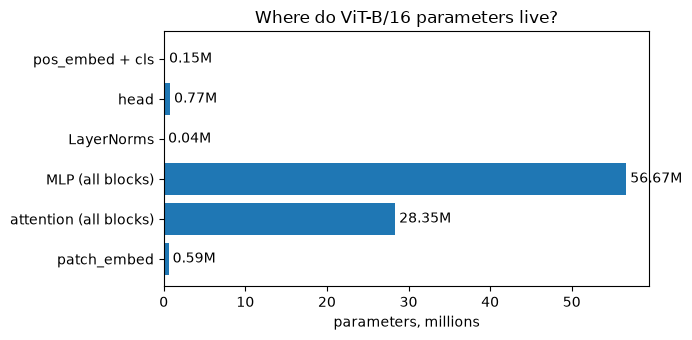

In [23]:
# Parameter budget of ViT-B/16
groups = {
    "patch_embed": vit_b16.patch_embed,
    "attention (all blocks)": nn.ModuleList([b.attn for b in vit_b16.blocks]),
    "MLP (all blocks)": nn.ModuleList([b.mlp for b in vit_b16.blocks]),
    "LayerNorms": nn.ModuleList([m for m in vit_b16.modules() if isinstance(m, nn.LayerNorm)]),
    "head": vit_b16.head,
}
budget = {k: sum(p.numel() for p in v.parameters()) for k, v in groups.items()}
budget["pos_embed + cls"] = vit_b16.pos_embed.numel() + vit_b16.cls_token.numel()

plt.figure(figsize=(7, 3.5))
plt.barh(list(budget.keys()), [v / 1e6 for v in budget.values()])
for i, v in enumerate(budget.values()):
    plt.text(v / 1e6 + 0.5, i, f"{v / 1e6:.2f}M", va="center")
plt.xlabel("parameters, millions")
plt.title("Where do ViT-B/16 parameters live?")
plt.tight_layout()
plt.show()
del vit_b16

<a id='Pretrained_Weights'></a>
# Sanity check: loading pretrained `timm` weights into our ViT

The best test of a from-scratch implementation: take a **pretrained** checkpoint from `timm`, load its `state_dict` into **our** model and check that both produce identical logits. If a single detail (qkv layout, LayerNorm eps, GELU flavour, order of residuals, pooling) is wrong, the outputs will differ.

We use `vit_small_patch16_224.augreg_in21k_ft_in1k` — ViT-S/16 pre-trained on ImageNet-21k and fine-tuned on ImageNet-1k with the AugReg recipe.

In [24]:
TIMM_NAME = "vit_small_patch16_224.augreg_in21k_ft_in1k"
timm_vit = timm.create_model(TIMM_NAME, pretrained=True).eval()

our_vit = VisionTransformer(img_size=224, patch_size=16, embed_dim=384, depth=12, num_heads=6, num_classes=1000).eval()
print(our_vit.load_state_dict(timm_vit.state_dict(), strict=True))
count_params(our_vit);

<All keys matched successfully>
Total params:     22.05M
Trainable params: 22.05M


In [25]:
data_cfg = resolve_data_config({}, model=timm_vit)
print("Preprocessing expected by the checkpoint:", data_cfg)
IMG_MEAN, IMG_STD = data_cfg["mean"], data_cfg["std"]

preprocess = T.Compose([
    T.ToPILImage(),
    T.Resize(224, interpolation=T.InterpolationMode.BICUBIC),
    T.CenterCrop(224),
    T.ToTensor(),
    T.Normalize(IMG_MEAN, IMG_STD),
])
batch = torch.stack([preprocess(img) for img in natural_images.values()])

with torch.no_grad():
    logits_timm = timm_vit(batch)
    logits_ours = our_vit(batch)
print("max |logits_timm - logits_ours| =", (logits_timm - logits_ours).abs().max().item())

Preprocessing expected by the checkpoint: {'input_size': (3, 224, 224), 'interpolation': 'bicubic', 'mean': (0.5, 0.5, 0.5), 'std': (0.5, 0.5, 0.5), 'crop_pct': 0.9, 'crop_mode': 'center'}


max |logits_timm - logits_ours| = 0.0


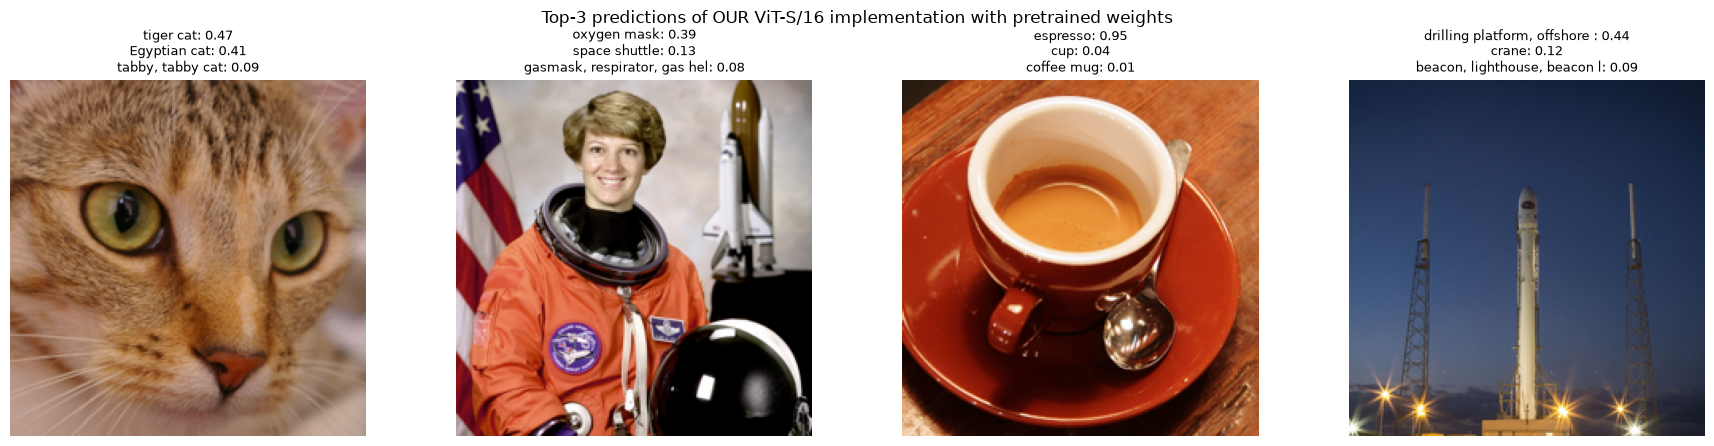

In [26]:
imagenet_info = ImageNetInfo()
probs = logits_ours.softmax(-1)
fig, axes = plt.subplots(1, len(natural_images), figsize=(18, 4.5))
for ax, img, name, p in zip(axes, batch, natural_images, probs):
    top = p.topk(3)
    ax.imshow(denormalize(img, IMG_MEAN, IMG_STD))
    ax.set_title("\n".join(
        f"{imagenet_info.index_to_description(i.item())[:28]}: {v:.2f}" for v, i in zip(top.values, top.indices)
    ), fontsize=9)
    ax.axis("off")
plt.suptitle("Top-3 predictions of OUR ViT-S/16 implementation with pretrained weights")
plt.tight_layout()
plt.show()

<a id='Looking_Inside'></a>
# Looking inside a ViT

Since we own the implementation, we can inspect everything. We reproduce three classic analyses from the ViT paper (Figure 7) and one popular attention visualization.

## 1. What does the patch embedding learn?

The rows of $\mathbf{E}$ are "filters" of size $16 \times 16 \times 3$. Visualizing the top principal components of $\mathbf{E}$ shows that ViT learns **Gabor-like / low-frequency basis functions** — very similar to the first layer of a CNN, even though nobody told it to.

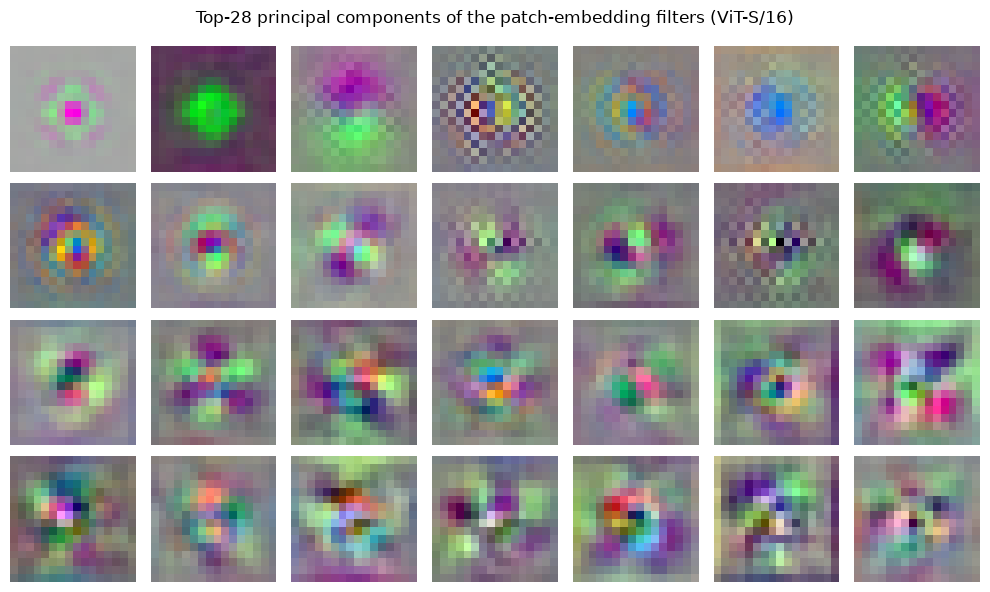

In [27]:
W = our_vit.patch_embed.proj.weight.detach()          # (D, 3, 16, 16)
W_flat = W.reshape(W.shape[0], -1)
W_flat = W_flat - W_flat.mean(0, keepdim=True)
_, _, V = torch.linalg.svd(W_flat, full_matrices=False)   # principal components of the filters
components = V[:28].reshape(28, 3, 16, 16)

fig, axes = plt.subplots(4, 7, figsize=(10, 6))
for ax, comp in zip(axes.flatten(), components):
    comp = (comp - comp.min()) / (comp.max() - comp.min())
    ax.imshow(comp.permute(1, 2, 0))
    ax.axis("off")
plt.suptitle("Top-28 principal components of the patch-embedding filters (ViT-S/16)")
plt.tight_layout()
plt.show()

## 2. Learned positional embeddings discovered 2D structure

We never told the model that the tokens come from a 2D grid: $\mathbf{E}_{pos}$ is a flat learned table. Yet the cosine similarity between learned position embeddings reveals **row and column structure** — compare with the hand-crafted sin-cos embeddings above.

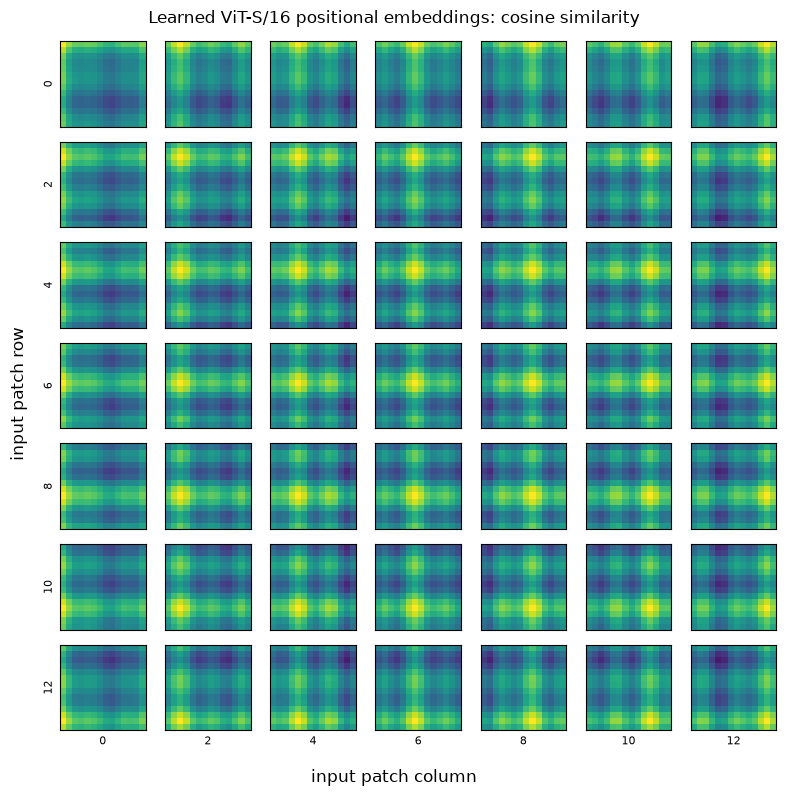

In [28]:
learned_pe = our_vit.pos_embed.detach()[0, 1:]      # drop [CLS]
plot_pos_embed_similarity(learned_pe, grid_size=14, title="Learned ViT-S/16 positional embeddings: cosine similarity", step=2)

## 3. Attention distance: local and global heads

For every head we compute the **mean attention distance** — the average pixel distance between a query patch and the patches it attends to, weighted by attention:

$$
\bar{d}_{\text{head}} = \frac{1}{N} \sum_{i=1}^{N} \sum_{j=1}^{N} A_{ij}\, \lVert \mathbf{pos}_i - \mathbf{pos}_j \rVert_2 .
$$

This is the ViT analogue of a receptive field. In a CNN the receptive field of the first layers is tiny by construction. In a ViT...

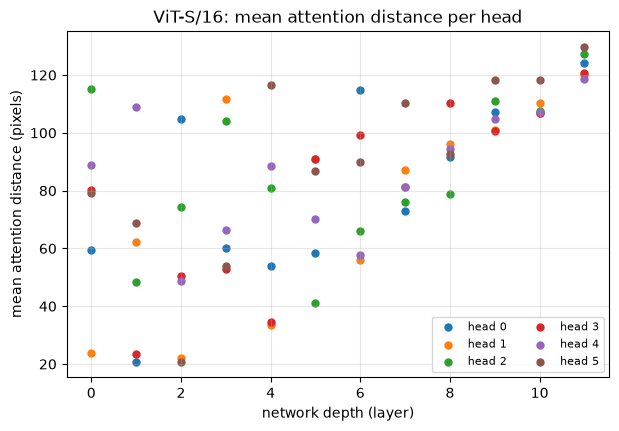

In [29]:
our_vit.set_store_attn(True)
with torch.no_grad():
    our_vit(batch)
attn_maps = our_vit.get_attn_maps()                  # L x (B, h, 1 + N, 1 + N)
our_vit.set_store_attn(False)

grid_size, patch_px = 14, 16
coords = torch.stack(torch.meshgrid(torch.arange(grid_size), torch.arange(grid_size), indexing="ij"), -1).reshape(-1, 2)
pixel_dist = torch.cdist(coords.float(), coords.float()) * patch_px      # (N, N) distance in pixels

mean_dist = []
for attn in attn_maps:
    a = attn[:, :, 1:, 1:]                             # patch-to-patch attention only
    a = a / a.sum(-1, keepdim=True)
    mean_dist.append((a * pixel_dist).sum(-1).mean(dim=(0, 2)))   # average over images and queries -> (h,)
mean_dist = torch.stack(mean_dist)                     # (L, h)

plt.figure(figsize=(7, 4.5))
for head in range(mean_dist.shape[1]):
    plt.scatter(range(len(mean_dist)), mean_dist[:, head], label=f"head {head}", s=25)
plt.xlabel("network depth (layer)")
plt.ylabel("mean attention distance (pixels)")
plt.title("ViT-S/16: mean attention distance per head")
plt.grid(alpha=0.3)
plt.legend(fontsize=8, ncol=2)
plt.show()

Even in the very first layers some heads attend **globally** (distance $\sim$ half the image), while others behave like local convolutions. With depth, all heads become global. The network *learns* a mix of local and global processing instead of having locality hard-wired. (Models trained on small data tend to learn *fewer* local heads in early layers — part of the reason they underperform CNNs there.)

## 4. What does [CLS] look at? Attention maps and Attention Rollout

The simplest visualization: the attention of the [CLS] query to all patch keys in the **last** layer, per head.

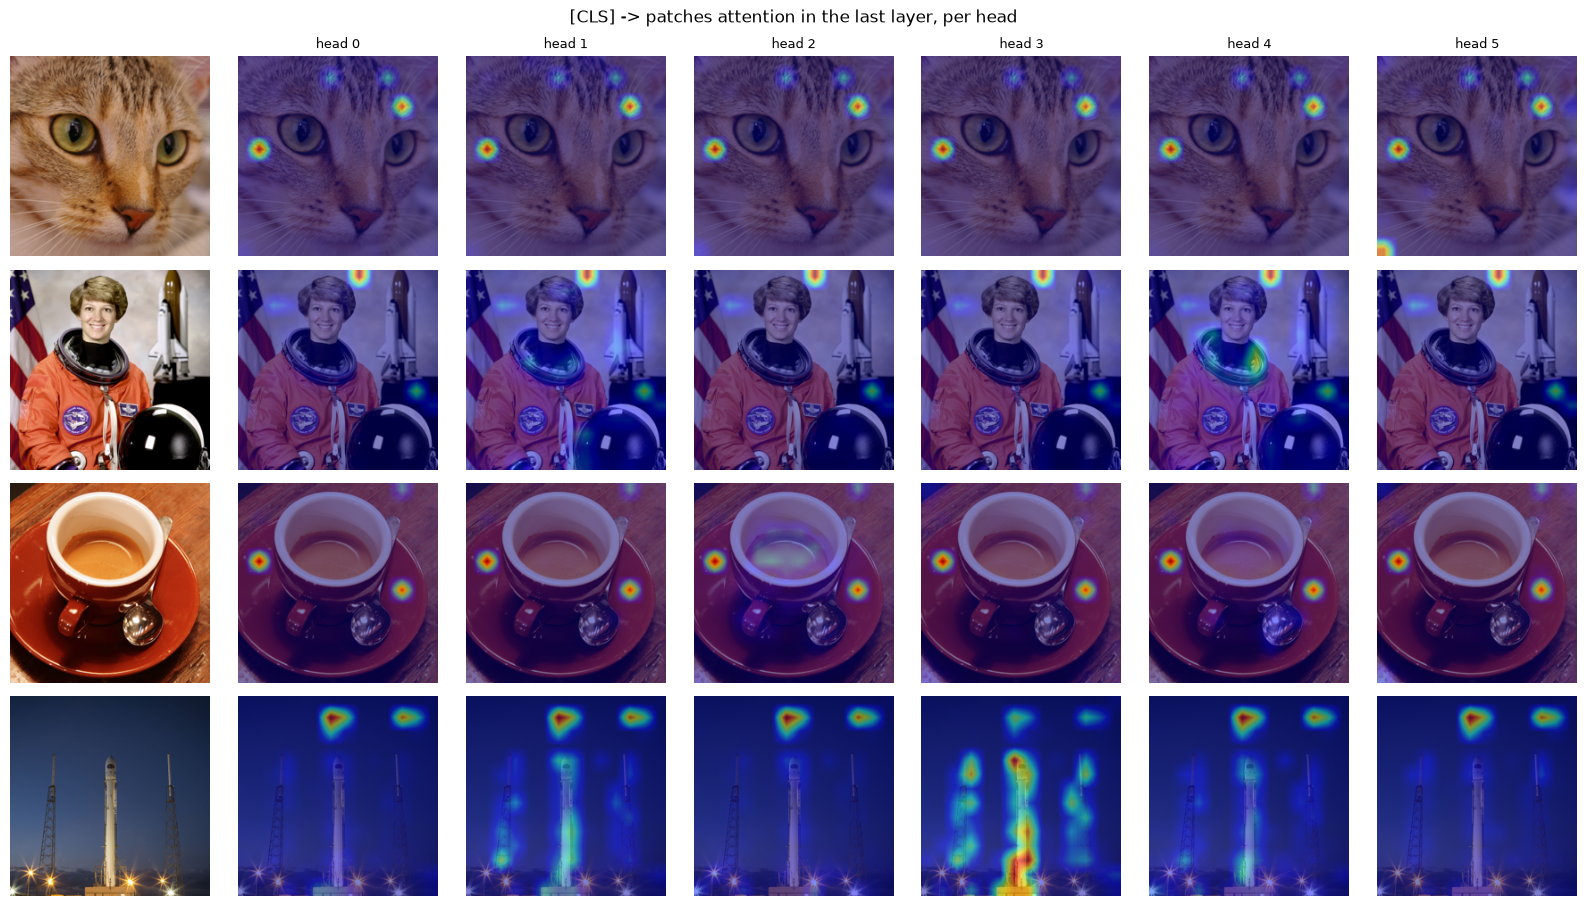

In [30]:
def cls_attention_last_layer(attn_maps, image_idx):
    last = attn_maps[-1][image_idx]                     # (h, 1 + N, 1 + N)
    return last[:, 0, 1:].reshape(-1, grid_size, grid_size)   # (h, 14, 14)


def overlay(ax, img, heatmap, title=None):
    heatmap = F.interpolate(heatmap[None, None], size=img.shape[:2], mode="bilinear")[0, 0]
    ax.imshow(img)
    ax.imshow(heatmap, cmap="jet", alpha=0.5)
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=9)


n_heads = attn_maps[0].shape[1]
fig, axes = plt.subplots(len(natural_images), n_heads + 1, figsize=(2.3 * (n_heads + 1), 2.3 * len(natural_images)))
for i in range(len(natural_images)):
    img = denormalize(batch[i], IMG_MEAN, IMG_STD)
    axes[i, 0].imshow(img); axes[i, 0].axis("off")
    for hh, amap in enumerate(cls_attention_last_layer(attn_maps, i)):
        overlay(axes[i, hh + 1], img, amap / amap.max(), title=f"head {hh}" if i == 0 else None)
plt.suptitle("[CLS] -> patches attention in the last layer, per head")
plt.tight_layout()
plt.show()

Raw attention of a single layer ignores how information was mixed in previous layers. **Attention Rollout** approximates the total flow of information from input patches to [CLS] by recursively multiplying attention matrices, accounting for the residual connection with the identity:

$$
\tilde{\mathbf{A}}_\ell = \frac{1}{2}\left(\bar{\mathbf{A}}_\ell + \mathbf{I}\right) \big/ \text{row-sum}, \qquad
\mathbf{R} = \tilde{\mathbf{A}}_L \tilde{\mathbf{A}}_{L-1} \cdots \tilde{\mathbf{A}}_1,
$$

where $\bar{\mathbf{A}}_\ell$ is the head-averaged attention of layer $\ell$. The row of $\mathbf{R}$ corresponding to [CLS] is the rollout map.

> ⚠️ Attention maps are **not** faithful explanations of the decision. They show where information flows, not why a class was predicted. Supervised ViTs often have noisy attention maps; self-supervised models such as DINO are known to produce remarkably clean object-centric maps.

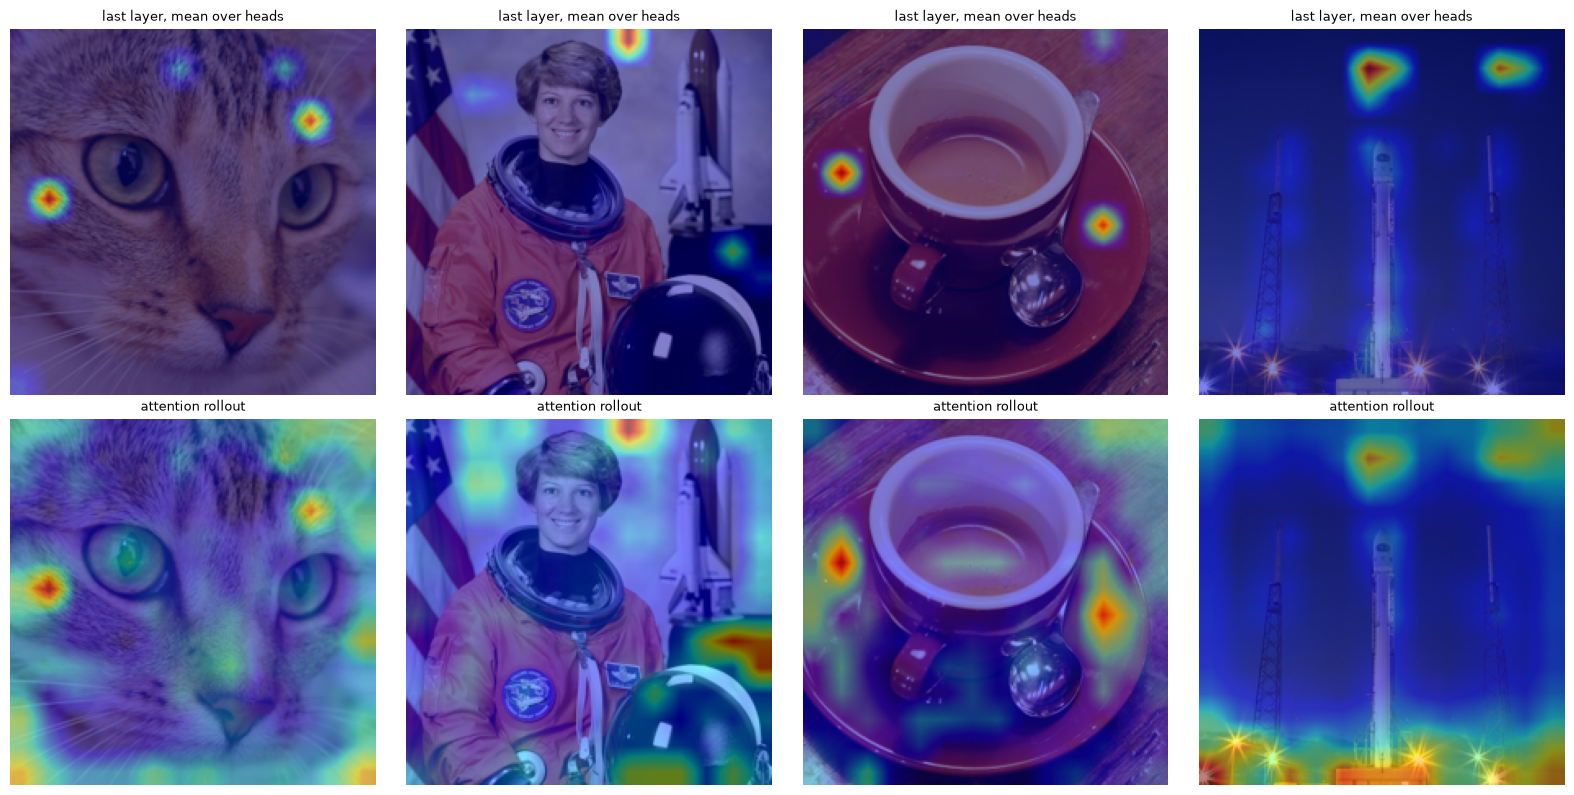

In [31]:
def attention_rollout(attn_maps, image_idx, head_fusion="mean"):
    result = None
    for attn in attn_maps:
        a = attn[image_idx]
        a = a.mean(0) if head_fusion == "mean" else a.max(0).values     # (1 + N, 1 + N)
        a = 0.5 * a + 0.5 * torch.eye(a.shape[-1])                       # residual connection
        a = a / a.sum(-1, keepdim=True)
        result = a if result is None else a @ result
    return result[0, 1:].reshape(grid_size, grid_size)


fig, axes = plt.subplots(2, len(natural_images), figsize=(4 * len(natural_images), 8))
for i in range(len(natural_images)):
    img = denormalize(batch[i], IMG_MEAN, IMG_STD)
    last = cls_attention_last_layer(attn_maps, i).mean(0)
    overlay(axes[0, i], img, last / last.max(), "last layer, mean over heads")
    roll = attention_rollout(attn_maps, i)
    overlay(axes[1, i], img, roll / roll.max(), "attention rollout")
plt.tight_layout()
plt.show()

<a id='Training'></a>
# Training ViT: from scratch vs CNN vs pretrained

Now let's train. We will run four experiments on CIFAR-10 with the **same** training loop:

| Run | Model | Init | Train data |
|---|---|---|---|
| `vit_scratch_100` | our ViT, $P=4$, $D=192$, $L=9$, $h=3$ (~4M params) | random | 100% (50k) |
| `resnet18_scratch_100` | ResNet-18 adapted to $32 \times 32$ (~11M params) | random | 100% (50k) |
| `vit_scratch_10` / `resnet18_scratch_10` | same | random | 10% (5k), 10x more epochs = **same number of steps** |
| `vit_pretrained_100` | our ViT-Ti/16 with timm ImageNet-21k (AugReg) weights at $112 \times 112$ | pretrained | 100%, 3 epochs |

> ⚠️ Two caveats to keep in mind when reading the results: the models are **not size-matched** (ResNet-18 has ~3x more parameters), and the recipe (AdamW, lr $10^{-3}$, 30 epochs) is a typical *ViT* recipe, not tuned for either model.

## The ViT training recipe

ViTs are much more sensitive to the optimization recipe than ResNets. The standard ingredients (DeiT / AugReg):

* **AdamW** (decoupled weight decay) with relatively large weight decay (0.05 — 0.3). SGD works poorly for ViTs.
* **No weight decay** on biases, LayerNorm parameters, positional embeddings and [CLS].
* **Linear warmup** followed by **cosine decay** of the learning rate. Warmup is essential: attention logits at initialization are unstable, and Adam's second-moment estimates are unreliable in the first steps.
* **Strong augmentation** (RandAugment/TrivialAugment, Mixup, CutMix) and **regularization** (stochastic depth, label smoothing) — they partially compensate for the missing inductive bias.
* **Gradient clipping** (norm 1.0) for stability.

Let's write this once in a `LightningModule`.

In [32]:
def param_groups_weight_decay(model: nn.Module, weight_decay: float):
    """AdamW param groups: no weight decay for biases, norms, positional embeddings and [CLS]."""
    decay, no_decay = [], []
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if p.ndim <= 1 or name.endswith(".bias") or "pos_embed" in name or "cls_token" in name:
            no_decay.append(p)
        else:
            decay.append(p)
    return [{"params": decay, "weight_decay": weight_decay}, {"params": no_decay, "weight_decay": 0.0}]


def warmup_cosine(step: int, total_steps: int, warmup_steps: int, min_lr_ratio: float = 0.01) -> float:
    """LR multiplier: linear warmup to 1, then cosine decay to `min_lr_ratio`."""
    if step < warmup_steps:
        return (step + 1) / max(1, warmup_steps)
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return min_lr_ratio + (1 - min_lr_ratio) * 0.5 * (1 + math.cos(math.pi * min(progress, 1.0)))


class LitClassifier(pl.LightningModule):
    def __init__(self, model, num_classes=10, lr=1e-3, weight_decay=0.05, warmup_ratio=0.1, label_smoothing=0.1):
        super().__init__()
        self.save_hyperparameters(ignore=["model"])
        self.model = model
        self.criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
        self.train_acc = MulticlassAccuracy(num_classes, average="micro")
        self.val_acc = MulticlassAccuracy(num_classes, average="micro")

    def forward(self, x):
        return self.model(x)

    def training_step(self, batch, batch_idx):
        x, y = batch
        logits = self(x)
        loss = self.criterion(logits, y)
        self.train_acc(logits, y)
        self.log("train_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        self.log("train_acc", self.train_acc, on_step=False, on_epoch=True)
        return loss

    def validation_step(self, batch, batch_idx):
        x, y = batch
        logits = self(x)
        self.val_acc(logits, y)
        self.log("val_loss", F.cross_entropy(logits, y), on_step=False, on_epoch=True)
        self.log("val_acc", self.val_acc, on_step=False, on_epoch=True, prog_bar=True)

    def configure_optimizers(self):
        optimizer = torch.optim.AdamW(
            param_groups_weight_decay(self.model, self.hparams.weight_decay), lr=self.hparams.lr, betas=(0.9, 0.999)
        )
        total_steps = self.trainer.estimated_stepping_batches
        warmup_steps = int(total_steps * self.hparams.warmup_ratio)
        scheduler = torch.optim.lr_scheduler.LambdaLR(
            optimizer, lambda step: warmup_cosine(step, total_steps, warmup_steps)
        )
        return [optimizer], [{"scheduler": scheduler, "interval": "step"}]

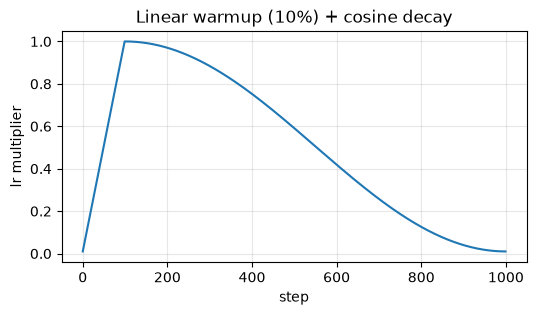

In [33]:
steps = np.arange(1000)
plt.figure(figsize=(6, 3))
plt.plot(steps, [warmup_cosine(s, 1000, 100) for s in steps])
plt.xlabel("step"); plt.ylabel("lr multiplier"); plt.title("Linear warmup (10%) + cosine decay")
plt.grid(alpha=0.3)
plt.show()

## Data pipeline and experiment runner

`TrivialAugmentWide` is a parameter-free cousin of RandAugment: for each image it samples one augmentation op and its strength uniformly. For the 10% setting we take a class-balanced subset.

In [34]:
CIFAR_MEAN, CIFAR_STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)


def cifar_transforms(img_size=32, mean=CIFAR_MEAN, std=CIFAR_STD):
    resize = [T.Resize(img_size, interpolation=T.InterpolationMode.BICUBIC)] if img_size != 32 else []
    train_tfms = T.Compose(resize + [
        T.RandomCrop(img_size, padding=img_size // 8, padding_mode="reflect"),
        T.RandomHorizontalFlip(),
        T.TrivialAugmentWide(),
        T.ToTensor(),
        T.Normalize(mean, std),
    ])
    val_tfms = T.Compose(resize + [T.ToTensor(), T.Normalize(mean, std)])
    return train_tfms, val_tfms


def balanced_subset_indices(targets, fraction, seed=95431):
    rng = np.random.default_rng(seed)
    targets = np.asarray(targets)
    idx = [rng.choice(np.flatnonzero(targets == c), int((targets == c).sum() * fraction), replace=False)
           for c in np.unique(targets)]
    return np.sort(np.concatenate(idx))


def make_loaders(fraction=1.0, img_size=32, mean=CIFAR_MEAN, std=CIFAR_STD, batch_size=256):
    train_tfms, val_tfms = cifar_transforms(img_size, mean, std)
    train_ds = torchvision.datasets.CIFAR10(DATA_DIR, train=True, transform=train_tfms)
    val_ds = torchvision.datasets.CIFAR10(DATA_DIR, train=False, transform=val_tfms)
    if fraction < 1.0:
        train_ds = Subset(train_ds, balanced_subset_indices(train_ds.targets, fraction))
    loader_kwargs = dict(num_workers=NUM_WORKERS, persistent_workers=NUM_WORKERS > 0, pin_memory=DEVICE == "cuda")
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, drop_last=True, **loader_kwargs)
    val_loader = DataLoader(val_ds, batch_size=512, shuffle=False, **loader_kwargs)
    return train_loader, val_loader


RESULTS = []


def run_experiment(name, model, train_loader, val_loader, n_epochs, **lit_kwargs):
    set_seed(95431)
    lit_model = LitClassifier(model, **lit_kwargs)
    loggers = [CSVLogger("logdirs", name=name)]
    if USE_WANDB:
        loggers.append(WandbLogger(project="kse_advanced_cv_M1L1", name=name, save_dir=f"logdirs/{name}"))
    trainer = pl.Trainer(
        max_epochs=n_epochs,
        accelerator="auto",
        devices=1,
        precision=PRECISION,
        logger=loggers,
        callbacks=[LearningRateMonitor(logging_interval="step")],
        gradient_clip_val=1.0,
        enable_checkpointing=False,
        enable_model_summary=False,
        log_every_n_steps=50,
    )
    start = time.time()
    try:
        trainer.fit(lit_model, train_loader, val_loader)
    finally:
        if USE_WANDB:
            wandb.finish()
    # keep a compact copy of the learning curves next to the notebook (plots below read from here)
    read_lightning_metrics(f"logdirs/{name}").to_csv(os.path.join(RESULTS_DIR, f"{name}_metrics.csv"), index=False)
    result = {
        "run": name,
        "params, M": round(sum(p.numel() for p in model.parameters()) / 1e6, 2),
        "train images": len(train_loader.dataset),
        "epochs": n_epochs,
        "val_acc": round(trainer.callback_metrics["val_acc"].item(), 4),
        "minutes": round((time.time() - start) / 60, 1),
    }
    RESULTS.append(result)
    pd.DataFrame(RESULTS).to_csv(os.path.join(RESULTS_DIR, "training_results.csv"), index=False)
    return result

## Experiment 1: ViT from scratch on 100% of CIFAR-10

Our ViT for $32 \times 32$ inputs: $P = 4$ ($8 \times 8 = 64$ patch tokens), $D = 192$, $L = 9$, $h = 3$, GAP pooling, stochastic depth 0.1.

> ⏱️ One epoch takes ~10 s on an RTX 5090 and ~40 s on an Apple M-series laptop. With `RUN_EXPERIMENTS = False` the cells below only load the precomputed results.

In [35]:
N_EPOCHS = 30


def cifar_vit():
    return VisionTransformer(
        img_size=32, patch_size=4, num_classes=10, embed_dim=192, depth=9, num_heads=3,
        drop_path_rate=0.1, global_pool="avg",
    )


def cifar_resnet18():
    # Standard CIFAR adaptation: 3x3 stem with stride 1 and no max-pooling (keep 32x32 resolution early on)
    model = timm.create_model("resnet18", pretrained=False, num_classes=10)
    model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
    model.maxpool = nn.Identity()
    return model


print(f"our CIFAR ViT: {sum(p.numel() for p in cifar_vit().parameters()) / 1e6:.2f}M params | "
      f"ResNet-18: {sum(p.numel() for p in cifar_resnet18().parameters()) / 1e6:.2f}M params")

if RUN_EXPERIMENTS:
    train_loader_100, val_loader = make_loaders(fraction=1.0)
    run_experiment("vit_scratch_100", cifar_vit(), train_loader_100, val_loader, N_EPOCHS, lr=1e-3, weight_decay=0.05)

our CIFAR ViT: 4.03M params | ResNet-18: 11.17M params


Using bfloat16 Automatic Mixed Precision (AMP)


GPU available: True (cuda), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


You are using a CUDA device ('NVIDIA GeForce RTX 5090') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Loading `train_dataloader` to estimate number of stepping batches.


`Trainer.fit` stopped: `max_epochs=30` reached.


## Experiment 2: ResNet-18 from scratch, same recipe

In [36]:
if RUN_EXPERIMENTS:
    run_experiment("resnet18_scratch_100", cifar_resnet18(), train_loader_100, val_loader, N_EPOCHS, lr=1e-3, weight_decay=0.05)

Using bfloat16 Automatic Mixed Precision (AMP)


GPU available: True (cuda), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Loading `train_dataloader` to estimate number of stepping batches.


`Trainer.fit` stopped: `max_epochs=30` reached.


## Experiment 3: only 10% of the data (5,000 images)

To compare "less data" and not "less training", we keep the **number of optimization steps** equal: 10x fewer images, 10x more epochs (300). The warmup and cosine schedule are therefore identical in steps. Where does the missing inductive bias hurt more?

In [37]:
if RUN_EXPERIMENTS:
    train_loader_10, _ = make_loaders(fraction=0.1)
    run_experiment("vit_scratch_10", cifar_vit(), train_loader_10, val_loader, N_EPOCHS * 10, lr=1e-3, weight_decay=0.05)
    run_experiment("resnet18_scratch_10", cifar_resnet18(), train_loader_10, val_loader, N_EPOCHS * 10, lr=1e-3,
                   weight_decay=0.05)

Using bfloat16 Automatic Mixed Precision (AMP)


GPU available: True (cuda), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


...

TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Loading `train_dataloader` to estimate number of stepping batches.


`Trainer.fit` stopped: `max_epochs=300` reached.


## Experiment 4: fine-tuning a pretrained ViT (with our implementation)

The practical answer to "ViTs are data hungry" is **transfer learning**: somebody else has already paid for the pre-training. We create our `VisionTransformer` in the ViT-Ti/16 configuration, but at resolution $112 \times 112$ ($7 \times 7 = 49$ tokens, similar to the scratch model), and load weights pre-trained on ImageNet-21k (`vit_tiny_patch16_224.augreg_in21k`, 14M images, 21k classes):

* the patch embedding and all blocks are loaded as is;
* the positional embedding is **resampled** from $14 \times 14$ to $7 \times 7$ with our `resample_pos_embed`;
* the 21k-class head is dropped and a new 10-class head is initialized.

Fine-tuning uses a 10x smaller learning rate and only 3 epochs.

In [38]:
def pretrained_vit_tiny(img_size=112, num_classes=10):
    model = VisionTransformer(img_size=img_size, patch_size=16, num_classes=num_classes, embed_dim=192, depth=12,
                              num_heads=3, drop_path_rate=0.1)
    state_dict = timm.create_model("vit_tiny_patch16_224.augreg_in21k", pretrained=True).state_dict()
    state_dict["pos_embed"] = resample_pos_embed(state_dict["pos_embed"], new_grid=img_size // 16)
    state_dict = {k: v for k, v in state_dict.items() if not k.startswith("head.")}
    missing, unexpected = model.load_state_dict(state_dict, strict=False)
    print("missing:", missing, "| unexpected:", unexpected)
    return model


if RUN_EXPERIMENTS:
    train_loader_ft, val_loader_ft = make_loaders(fraction=1.0, img_size=112, mean=(0.5,) * 3, std=(0.5,) * 3,
                                                  batch_size=128)
    run_experiment("vit_pretrained_100", pretrained_vit_tiny(), train_loader_ft, val_loader_ft, n_epochs=3,
                   lr=1e-4, weight_decay=0.05)

Using bfloat16 Automatic Mixed Precision (AMP)


GPU available: True (cuda), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Loading `train_dataloader` to estimate number of stepping batches.


missing: ['head.weight', 'head.bias'] | unexpected: []


`Trainer.fit` stopped: `max_epochs=3` reached.


## Results

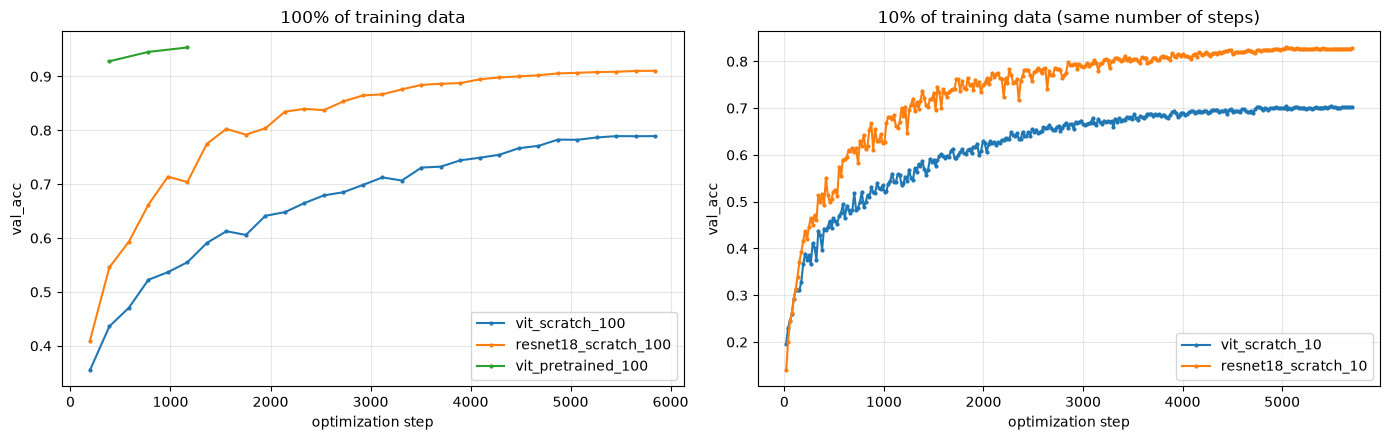

,run,"params, M",train images,epochs,val_acc,minutes
0,vit_scratch_100,4.03,50000,30,0.7892,3.8
1,resnet18_scratch_100,11.17,50000,30,0.9105,3.8
2,vit_scratch_10,4.03,5000,300,0.7025,6.8
3,resnet18_scratch_10,11.17,5000,300,0.8276,6.7
4,vit_pretrained_100,5.50,50000,3,0.9537,1.0


In [39]:
def load_metrics(name):
    return pd.read_csv(os.path.join(RESULTS_DIR, f"{name}_metrics.csv"))


def plot_val_acc(names, ax, title):
    for name in names:
        df = load_metrics(name).dropna(subset=["val_acc"])
        # x-axis in optimization steps, so that 100% and 10% runs are directly comparable
        ax.plot(df["step"], df["val_acc"], marker="o", markersize=2, label=name)
    ax.set_xlabel("optimization step"); ax.set_ylabel("val_acc"); ax.set_title(title)
    ax.grid(alpha=0.3); ax.legend()


fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_val_acc(["vit_scratch_100", "resnet18_scratch_100", "vit_pretrained_100"], axes[0], "100% of training data")
plot_val_acc(["vit_scratch_10", "resnet18_scratch_10"], axes[1], "10% of training data (same number of steps)")
plt.tight_layout()
plt.show()

results_df = pd.read_csv(os.path.join(RESULTS_DIR, "training_results.csv"))
results_df

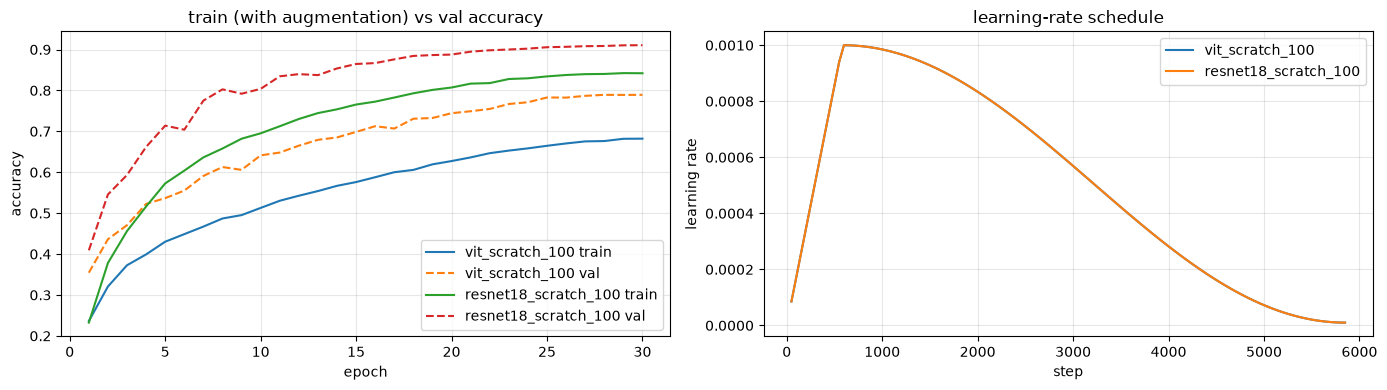

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name in ["vit_scratch_100", "resnet18_scratch_100"]:
    df = load_metrics(name)
    tr = df.dropna(subset=["train_acc"])
    va = df.dropna(subset=["val_acc"])
    axes[0].plot(tr["epoch"] + 1, tr["train_acc"], label=f"{name} train")
    axes[0].plot(va["epoch"] + 1, va["val_acc"], "--", label=f"{name} val")
    lr = df.dropna(subset=[c for c in df.columns if c.startswith("lr-")][:1])
    axes[1].plot(lr["step"], lr[[c for c in df.columns if c.startswith("lr-")][0]], label=name)
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("accuracy"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[0].set_title("train (with augmentation) vs val accuracy")
axes[1].set_xlabel("step"); axes[1].set_ylabel("learning rate"); axes[1].legend(); axes[1].grid(alpha=0.3)
axes[1].set_title("learning-rate schedule")
plt.tight_layout()
plt.show()

### Takeaways

* With the **same** recipe and budget, the ResNet trained from scratch beats our ViT on CIFAR-10 by ~12 points — convolutions' locality and weight sharing are exactly the right prior for small images and small data (keep the caveats in mind: ResNet-18 is ~3x larger, and the recipe was not tuned for either model).
* With 10x less data **and the same number of optimization steps**, both models lose ~8 points and the gap stays about the same. At CIFAR scale both 50k and 5k images are "small data" for a ViT: the data-hunger effect from the ViT paper shows up between ~1M (ImageNet-1k) and 300M (JFT) images, where the ViT *catches up and overtakes* the CNN.
* **A lesson in experimental design:** if we keep the number of *epochs* fixed instead (10x fewer steps on the 10% subset), the gap appears to grow from 12 to 15 points — but that measures "less training", not "less data". Always control the optimization budget when comparing data regimes.
* A **pretrained** ViT fine-tuned for just 3 epochs beats both from-scratch models by a large margin. In practice you almost never train a ViT from scratch: you choose a good pretrained checkpoint (supervised, self-supervised or CLIP-like) and adapt it.
* ViTs trained from scratch *can* match CNNs on small datasets, but it takes much longer schedules (hundreds of epochs), heavier augmentation (Mixup/CutMix), and architectural tweaks — the topic of the next lecture (DeiT, hybrid and hierarchical models).

<a id='Summary'></a>
# Summary

* A ViT turns an image into a **sequence of patch tokens** (a strided convolution), adds **positional embeddings** and a **[CLS]** token, and processes them with a stack of standard **pre-norm Transformer blocks**.
* **Self-attention** is a data-dependent, global weighted average; it is permutation-equivariant (hence positional embeddings) and costs $\mathcal{O}(N^2)$ in the number of tokens (hence patches, and the efficient architectures of the next lecture).
* ViTs have **weak inductive biases**: they learn locality, 2D structure and Gabor-like filters from data. That makes them data-hungry when trained from scratch, but extremely strong and scalable when pre-trained.
* The training **recipe** matters as much as the architecture: AdamW, warmup + cosine, no decay on norms/embeddings, strong augmentation, stochastic depth.
* Because parameters do not depend on the sequence length, a ViT can run at a new resolution after **interpolating the positional embeddings**.

# Self-check questions

**Theory**
1. Show that a linear projection of non-overlapping patches is equivalent to a convolution. What are its kernel size, stride and number of output channels?
2. Why is the dot product in attention divided by $\sqrt{d}$? What happens to the softmax and its gradients without it?
3. Prove that self-attention without positional embeddings is permutation-equivariant. Is the [CLS] output of such a ViT permutation-invariant? What does it imply for a ViT with global average pooling?
4. What is the difference between pre-norm and post-norm blocks? Explain the result of our warmup experiment.
5. Compare the [CLS] token and global average pooling. Can a ViT work without [CLS]?
6. Why does a ViT lose to a ResNet when both are trained from scratch on a small dataset? Name three ways to fix it.
7. Why don't we apply weight decay to positional embeddings, [CLS] and LayerNorm parameters?
8. What does the mean attention distance of heads in early layers tell us about how ViTs differ from CNNs? Why is attention rollout not a faithful explanation of a prediction?

**Practice**
1. ViT-B/16 ($D = 768$, $h = 12$) at $384 \times 384$: compute $N$, the fp16 memory of one attention matrix per head per layer, and the MACs of $\mathbf{Q}\mathbf{K}^\top$ vs the `qkv` projection in one layer. Which term dominates? At what resolution do they become equal?
2. A ViT pre-trained at $224 \times 224$ with $P = 16$ must be fine-tuned at $448 \times 448$. Which parameters change shape and how do you initialize them? Write the code.
3. Your from-scratch ViT loads a `timm` checkpoint with `strict=True`, but the logits differ from `timm` by ~0.3. List four bugs that a matching `state_dict` cannot detect.
4. Count the parameters of ViT-S/16 (224px, 1000 classes) by hand: patch embedding, positional embedding, one block, head. Compare with `count_params`.

<a id='Practical_Tips'></a>
# Appendix: practical tips for fine-tuning ViTs

Not covered in class in detail — a reference for practical work.

## Fine-tuning a pretrained ViT

| Trick | Why |
|---|---|
| **Use the preprocessing of the checkpoint** (`timm.data.resolve_data_config`) | AugReg models use mean = std = 0.5, others ImageNet stats, CLIP its own — mismatch silently costs accuracy |
| **Fine-tune at a higher resolution** than pre-training (+ interpolate $\mathbf{E}_{pos}$) | more tokens = more detail; standard trick (224 $\rightarrow$ 384) |
| **Layer-wise learning-rate decay** (LLRD): $\text{lr}_\ell = \text{lr} \cdot \gamma^{L-\ell}$, $\gamma \approx 0.65 - 0.85$ | lower layers hold generic features, change them less (standard for BEiT / MAE / DINOv2 fine-tuning) |
| **Warmup + cosine, AdamW, small LR** ($10^{-5} - 10^{-4}$) | large updates destroy pretrained features |
| **Stochastic depth** 0.1 — 0.2 | cheap and effective regularizer |
| **Linear probe first** (freeze backbone, train head), then full fine-tune | a quick estimate of representation quality |
| **Gradient checkpointing** (`model.set_grad_checkpointing()` in timm) | trade compute for memory with long sequences |

## Typical bugs in from-scratch implementations

* forgetting the $1/\sqrt{d}$ scale, or applying softmax over the wrong dimension (must be over **keys**);
* wrong `reshape`/`permute` order for `qkv` (heads get mixed with tokens — the model still trains, just badly);
* a positional-embedding table of the wrong length (forgetting the $+1$ for [CLS]) — broadcasting can hide the bug when the batch has a single image;
* a mismatch in LayerNorm `eps` or GELU flavour (`tanh` approximation vs exact) — `load_state_dict(strict=True)` passes, but the logits differ;
* applying weight decay to positional embeddings / [CLS] / LayerNorm;
* using `nn.MultiheadAttention` without `batch_first=True` (it expects `(N, B, D)` by default).

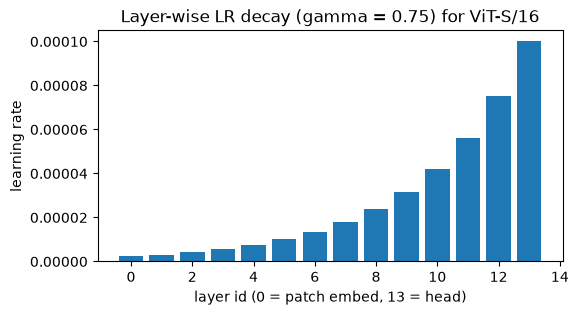

In [41]:
def llrd_param_groups(model: VisionTransformer, lr: float, weight_decay: float, decay: float = 0.75):
    """Layer-wise learning-rate decay for our VisionTransformer (a common fine-tuning recipe)."""
    num_layers = len(model.blocks) + 1
    groups = {}
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if name.startswith(("patch_embed", "cls_token", "pos_embed")):
            layer_id = 0
        elif name.startswith("blocks."):
            layer_id = int(name.split(".")[1]) + 1
        else:  # final norm and head
            layer_id = num_layers
        no_wd = p.ndim <= 1 or name.endswith(".bias") or name in ("pos_embed", "cls_token")
        key = (layer_id, no_wd)
        if key not in groups:
            groups[key] = {"params": [], "lr": lr * decay ** (num_layers - layer_id),
                           "weight_decay": 0.0 if no_wd else weight_decay}
        groups[key]["params"].append(p)
    return list(groups.values())


groups = llrd_param_groups(our_vit, lr=1e-4, weight_decay=0.05)
lrs = sorted({g["lr"] for g in groups})
plt.figure(figsize=(6, 3))
plt.bar(range(len(lrs)), lrs)
plt.xlabel("layer id (0 = patch embed, 13 = head)"); plt.ylabel("learning rate")
plt.title("Layer-wise LR decay (gamma = 0.75) for ViT-S/16")
plt.show()